# Hiperparámetros de modelos de ML con metaheurísticas

**Aplicación de metaheurísticas a Machine Learning (1/2)** · pronóstico de demanda eléctrica con modelos de scikit-learn

Esta notebook cierra el repositorio llevando todo lo visto (búsqueda local, recocido simulado, algoritmos genéticos, PSO, evolución diferencial, medición de desempeño y ajuste de parámetros) a un problema real de ingeniería: **elegir los hiperparámetros de un modelo de pronóstico de demanda de energía eléctrica**. La notebook siguiente ([17 · selección de características](17-seleccion-de-caracteristicas-metaheuristicas.ipynb)) usa la misma serie sintética para el problema binario de escoger variables.

**Tabla de contenido**

1. Marco teórico: HPO como optimización de caja negra
2. Codificación de individuos y manejo de restricciones
3. Qué dice la literatura (resumen cualitativo)
4. Datos sintéticos de demanda horaria y validación temporal
5. Modelos y espacio de búsqueda mixto/condicional
6. El evaluador: caché, presupuesto y ruido
7. Los optimizadores desde cero (Grid, Random, ES(1+1), GA con memoria, PSO, SA, DE, BO con GP)
8. Experimento: mismo presupuesto, varias réplicas
9. Convergencia, significancia y mejores hiperparámetros
10. Predicción vs real en el conjunto de prueba
11. Costo computacional y riesgo de sobreajuste al conjunto de validación
12. Cómo llevar esto a un Transformer/PyTorch
13. Ventajas y limitaciones, resumen, ejercicios y referencias

## Qué vas a aprender / Prerrequisitos

**Qué vas a aprender**

- Formular la búsqueda de hiperparámetros (HPO) como un problema de optimización **caja negra, costoso, ruidoso, de espacio mixto y condicional**.
- Diseñar una **codificación unificada** en $[0,1]^d$ que permite usar el mismo optimizador sobre variables enteras, continuas, categóricas y condicionales.
- Implementar desde cero y comparar bajo el **mismo presupuesto de evaluaciones**: Grid, Random Search, estrategia evolutiva $(1+1)$, algoritmo genético de estado estable con **memoria**, PSO, recocido simulado, evolución diferencial y una optimización bayesiana simple con proceso gaussiano.
- Usar **memoización** del fitness, evaluaciones con **múltiples semillas**, pruebas de significancia entre optimizadores y un conjunto de **prueba final** que el optimizador nunca ve.
- Medir el costo en tiempo y el **optimismo** (sobreajuste al conjunto de validación) del mejor valor encontrado.

**Prerrequisitos**: [09 · algoritmos genéticos](../03-metodos-poblacionales/09-algoritmos-geneticos.ipynb), [11 · PSO y DE](../03-metodos-poblacionales/11-enjambre-pso-evolucion-diferencial.ipynb), [05 · recocido simulado](../01-metodos-de-trayectoria/05-aleatorizados-recocido-simulado.ipynb), [14 · medición de desempeño](../05-evaluacion-y-ajuste/14-medicion-de-desempeno.ipynb) y [15 · ajuste de parámetros](../05-evaluacion-y-ajuste/15-ajuste-de-parametros.ipynb). Conocer regresión con scikit-learn.

> **Alcance honesto.** Todo corre en CPU con `n_jobs=1`, sobre una serie **sintética** y modelos pequeños (Ridge, gradient boosting, MLP) para que la notebook ejecute en pocos minutos. Con presupuestos de decenas de evaluaciones y 5 réplicas por algoritmo, las diferencias finas entre metaheurísticas **no** son concluyentes; lo que sí se puede estudiar con rigor es la metodología (caché, presupuesto igual, validación temporal, prueba final).

In [1]:
import time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from threadpoolctl import threadpool_limits

threadpool_limits(1)                     # un solo hilo: costos comparables y reproducibles
warnings.filterwarnings("ignore")
SEMILLA = 2024
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("Listo. Semilla global:", SEMILLA)

Listo. Semilla global: 2024


## 1. Marco teórico: HPO como optimización de caja negra

Un modelo de ML tiene **parámetros** $\theta$ (pesos, aprendidos al entrenar) e **hiperparámetros** $\lambda$ (profundidad de árboles, tasa de aprendizaje, número de neuronas, ventana de rezagos...) fijados *antes* de entrenar. Dado un algoritmo de aprendizaje $\mathcal{A}$ y un espacio de configuraciones $\Lambda$, el problema es

$$
\lambda^\star \;=\; \arg\min_{\lambda \in \Lambda} \; f(\lambda), \qquad
f(\lambda) \;=\; \mathbb{E}_{s}\Big[\, \mathcal{L}\big(\mathcal{A}_{\lambda,s}(\mathcal{D}_{\text{train}}),\; \mathcal{D}_{\text{val}}\big) \Big],
$$

donde $s$ es la semilla aleatoria del entrenamiento (inicialización, orden de los lotes, submuestreo) y $\mathcal{L}$ una métrica de error de validación. En pronóstico de demanda usamos el **MAPE** (el mismo fitness del trabajo de referencia):

$$
\text{MAPE}(y,\hat y)=\frac{100}{n}\sum_{t=1}^{n}\left|\frac{y_t-\hat y_t}{y_t}\right| ,\qquad
\text{RMSE}(y,\hat y)=\sqrt{\frac1n\sum_{t=1}^{n}(y_t-\hat y_t)^2}.
$$

Las cinco propiedades que hacen de HPO un terreno natural para metaheurísticas:

| Propiedad | Qué significa | Consecuencia para el optimizador |
|---|---|---|
| **Caja negra** | $f$ no tiene fórmula ni gradiente accesible respecto a $\lambda$ (hay un entrenamiento de por medio) | Solo métodos de orden cero: se evalúa y se compara |
| **Costosa** | Cada evaluación = un entrenamiento completo (segundos a horas) | El **presupuesto** $B$ de evaluaciones es pequeño; importa cada evaluación y la caché |
| **Ruidosa** | $f$ depende de la semilla $s$: dos evaluaciones del mismo $\lambda$ difieren | Comparar con una sola evaluación puede engañar; réplicas y re-evaluación final |
| **Espacio mixto** | Entero (capas), continuo y en escala log (tasa de aprendizaje), categórico (activación, familia de modelo) | Codificación y operadores de variación adecuados a cada tipo |
| **Condicional / con restricciones** | Algunos hiperparámetros solo existen si otro toma cierto valor; otros deben cumplir relaciones entre sí | Operadores de **reparación**, decodificadores válidos por construcción o penalizaciones |

Dos observaciones adicionales que conviene tener presentes:

- **Baja dimensión efectiva.** Típicamente solo unos pocos hiperparámetros importan mucho para un problema dado (Bergstra y Bengio, 2012). Esto explica por qué *random search* es una línea base tan difícil de superar y por qué la grilla desperdicia evaluaciones: una grilla con $k$ niveles en $d$ dimensiones solo prueba $k$ valores distintos de cada hiperparámetro, mientras que $k^d$ puntos aleatorios prueban $k^d$ valores distintos de cada uno.
- **Paisaje no suave y con mesetas.** Muchos hiperparámetros tienen efecto casi nulo en cierta región (mesetas), y los que no están activos (ramas condicionales) generan *idénticas* configuraciones efectivas: ¡la memoización las detecta!

## 2. Codificación de individuos y manejo de restricciones

Para que cualquier metaheurística opere sobre cualquier tipo de variable se usa una **codificación unificada**: el individuo es un vector $u\in[0,1]^d$ y un **decodificador** $\phi:[0,1]^d\to\Lambda$ lo transforma en una configuración válida.

| Tipo de hiperparámetro | Decodificación $\phi_i(u_i)$ | Ejemplo |
|---|---|---|
| Continuo lineal | $a + u_i (b-a)$ | `dropout` en $[0.0, 0.5]$ |
| Continuo en escala log | $\exp\!\big(\ln a + u_i(\ln b-\ln a)\big)$ | tasa de aprendizaje en $[10^{-4},10^{-2}]$ |
| Entero | $\text{round}(a + u_i(b-a))$ | nº de neuronas, profundidad |
| Categórico con $K$ niveles | $\lfloor K u_i\rfloor$ (K celdas iguales) | activación $\in\{\text{relu},\tanh\}$ |
| Condicional | el gen se **ignora** si su rama no está activa | `alpha` de Ridge solo si familia = Ridge |

**Ventajas.** Un solo conjunto de operadores (mutación gaussiana, cruce uniforme/aritmético, velocidades de PSO, diferencias de DE) sirve para todos los tipos, y todo individuo decodifica a una configuración *válida por construcción*.
**Costo.** Las variables categóricas quedan con una "geometría" artificial (la categoría 0 está "cerca" de la 1 pero "lejos" de la 2), y genes inactivos son *neutrales* (cambiarlos no cambia el fitness). Esto último es un rasgo, no un defecto: permite memoización por configuración efectiva.

### Restricciones entre hiperparámetros

En el trabajo de referencia con Transformers, `num_heads` debe **dividir** a la dimensión del modelo $d_{\text{model}}$. Hay tres estrategias estándar:

1. **Decodificador válido por construcción**: en vez de muestrear `num_heads` libremente, se muestrea un índice $j\in\{0,\dots,m-1\}$ dentro de la lista de divisores de $d_{\text{model}}$. Es la estrategia más limpia (el espacio factible *es* el espacio de búsqueda).
2. **Reparación**: se genera libremente y luego se proyecta al valor factible más cercano (p. ej. el divisor de $d_{\text{model}}$ más próximo a lo propuesto).
3. **Penalización**: se asigna un fitness grande a individuos infactibles. Es la peor opción para HPO porque desperdicia una evaluación (o varias) y deforma el paisaje.

Aquí aplicaremos (1) y (2) en una función pequeña, y la dependencia condicional por familia de modelo se resuelve decodificando solo los genes activos.

In [2]:
def divisores(n):
    """Todos los divisores positivos de n (para restricciones tipo 'num_heads divide d_model')."""
    return [k for k in range(1, n + 1) if n % k == 0]

def decodificar_heads(u_gen, d_model, heads_max=16):
    """Estrategia 1: el gen indexa la lista de divisores factibles (válido por construcción)."""
    validos = [h for h in divisores(d_model) if h <= heads_max]
    return validos[min(int(u_gen * len(validos)), len(validos) - 1)]

def reparar_heads(h_propuesto, d_model):
    """Estrategia 2: proyectar a un divisor factible (el más cercano en escala log)."""
    validos = divisores(d_model)
    return min(validos, key=lambda h: abs(np.log(h) - np.log(max(h_propuesto, 1))))

print("Divisores de 24:", divisores(24))
print("Decodificar u=0.0,0.3,0.6,0.99 con d_model=24 ->", [decodificar_heads(u, 24) for u in (0.0, 0.3, 0.6, 0.99)])
print("Reparar propuestas 5, 7, 10 con d_model=24 ->", [reparar_heads(h, 24) for h in (5, 7, 10)])
assert all(24 % decodificar_heads(u, 24) == 0 for u in np.linspace(0, 1, 101))
assert all(24 % reparar_heads(h, 24) == 0 for h in range(1, 40))

Divisores de 24: [1, 2, 3, 4, 6, 8, 12, 24]
Decodificar u=0.0,0.3,0.6,0.99 con d_model=24 -> [1, 3, 6, 12]
Reparar propuestas 5, 7, 10 con d_model=24 -> [6, 8, 12]


## 3. Qué dice la literatura (resumen cualitativo)

**Línea base y métodos secuenciales.** Bergstra y Bengio (2012) mostraron que la búsqueda aleatoria supera a la grilla a igual presupuesto cuando pocos hiperparámetros son relevantes. Los métodos basados en modelo sustituto (optimización bayesiana con procesos gaussianos, Snoek et al. 2012; estimadores Parzen, Bergstra et al. 2011; SMAC, Hutter et al. 2011) construyen un modelo de $f$ y maximizan una función de adquisición como la mejora esperada (Jones et al. 1998). Hyperband (Li et al. 2018) ataca el costo con *multi-fidelidad* (descartar pronto configuraciones malas). Feurer y Hutter (2019) sintetizan este campo en el libro *Automated Machine Learning*.

**Metaheurísticas para HPO.** Las estrategias evolutivas con adaptación (Hansen y Ostermeier, 2001, CMA-ES) y los algoritmos genéticos han sido usados durante años para ajustar SVM (p. ej. Lessmann et al., 2005) y redes; Real et al. (2019) usan evolución "regularizada" para arquitecturas de redes. La revisión de Abd Elaziz et al. (2021) cataloga técnicas metaheurísticas avanzadas aplicadas a redes neuronales profundas.

**En pronóstico de carga y energía** (el marco de un proyecto de referencia de pronóstico de demanda con Transformers), el patrón de la literatura revisada es:

| Dominio | Modelo ajustado | Metaheurísticas usadas (cualitativo) |
|---|---|---|
| Pronóstico de demanda eléctrica a corto plazo | Transformer | **Evolución diferencial** comparada con GA y PSO, con MSE/MAPE como objetivo (Sen, Mazumder y Sen, 2023) |
| Pronóstico de carga energética | Redes profundas recurrentes y otras | Variedad de algoritmos de enjambre/evolutivos, que reportan mejora frente a hiperparámetros fijados a mano (Bacanin et al., 2023) |
| Generación solar / radiación solar | LSTM/GRU y otros recurrentes | Enjambre, genético y variantes híbridas para elegir capas, neuronas y tasa de aprendizaje (revisiones sistemáticas del área) |
| Regresión/clasificación con SVM y SVR | SVM, SVR | PSO y otras para $C$, $\gamma$ y $\varepsilon$: espacio pequeño y continuo, donde las metaheurísticas funcionan bien |

Dos lecciones transversales que esta notebook busca poner a prueba en lugar de aceptarlas por fe: (i) *es frecuente comparar algoritmos con presupuestos distintos o con una sola corrida*, lo que infla las diferencias; (ii) *el fitness se evalúa sobre el mismo conjunto en el que se reporta la mejora*, lo que introduce optimismo. En el proyecto de referencia, el modelo base era un Transformer con 7 hiperparámetros discretos y fitness MAPE; un GA de estado estable **con memoria** y una estrategia $(1+1)$ se compararon contra el modelo base. Aquí reproducimos el marco metodológico con modelos baratos.

## 4. Datos sintéticos de demanda horaria y validación temporal

Generamos una serie horaria de **demanda eléctrica** (MW) con semilla fija. Componentes:

$$
y_t = \underbrace{b\,(1+\gamma t)}_{\text{tendencia}} + \underbrace{s^{d}_{h(t)}}_{\text{ciclo diario (2 picos)}} + \underbrace{s^{w}_{\text{dow}(t)}}_{\text{ciclo semanal}} + \underbrace{g(T_t)}_{\text{efecto temperatura}} + \underbrace{c\,\mathbb{1}[\text{festivo}]}_{\text{festivos}} + \underbrace{\eta_t}_{\text{ruido AR(1)}}
$$

La temperatura tiene ciclo diario, componente lenta y un proceso AR(1) (frentes meteorológicos); $g(T)=a\,(T-T_c)_+^{1.3}+b\,(T_h-T)_+^{1.5}$ modela enfriamiento (calor) y calefacción (frío), por lo que el efecto es **no lineal**.

**Validación temporal.** Nada de `train_test_split` aleatorio en series: mezclaría el futuro con el pasado (fuga de información). Usamos tres bloques contiguos y en orden: *entrenamiento → validación (el optimizador lo ve) → prueba (el optimizador nunca lo ve)*. El pronóstico es **a un día de antelación** (*day-ahead*): los rezagos de demanda disponibles son $\ge 24$ h; el calendario y la temperatura se consideran conocidos (pronóstico meteorológico).

(4560, 3) | rango: 2023-01-01 00:00:00 -> 2023-07-09 23:00:00
           mean    std    min     max
demanda  1011.7  127.4  667.1  1386.7
temp       21.8    5.3    8.7    35.9
festivo     0.0    0.2    0.0     1.0


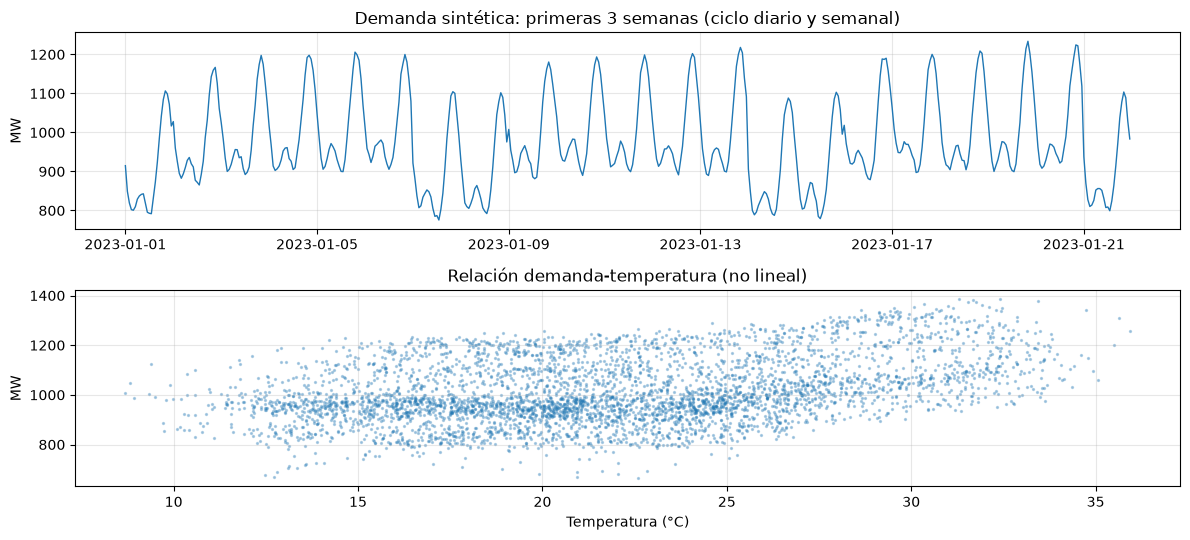

In [3]:
def generar_demanda(dias=190, seed=0):
    """Serie horaria sintética: tendencia + ciclo diario + semanal + temperatura + festivos + ruido AR(1)."""
    rng = np.random.default_rng(seed)
    n = dias * 24
    idx = pd.date_range("2023-01-01", periods=n, freq="h")
    h, dow, doy = idx.hour.values, idx.dayofweek.values, idx.dayofyear.values
    ar = np.zeros(n)                                    # componente meteorológica lenta
    for t in range(1, n):
        ar[t] = 0.995 * ar[t - 1] + rng.normal(0, 0.35)
    temp = 22 + 3 * np.sin(2 * np.pi * (doy - 100) / 365) + 4 * np.sin(2 * np.pi * (h - 9) / 24) + ar
    festivo = np.zeros(n, bool)
    for d in rng.choice(np.arange(dias), size=max(3, dias // 25), replace=False):
        festivo[d * 24:(d + 1) * 24] = True
    tendencia = 1000 * (1 + 0.0003 * np.arange(n) / 24)
    diario = 120 * np.sin(2 * np.pi * (h - 14) / 24) + 80 * np.sin(4 * np.pi * (h - 5) / 24)
    semanal = np.where(dow >= 5, -110, 0) + np.where(dow == 0, -20, 0)
    clima = 9.0 * np.maximum(temp - 24, 0) ** 1.3 + 2.0 * np.maximum(18 - temp, 0) ** 1.5
    efecto_fest = np.where(festivo, -140, 0)
    ruido = np.zeros(n)
    for t in range(1, n):
        ruido[t] = 0.8 * ruido[t - 1] + rng.normal(0, 8)
    y = tendencia + diario + semanal + clima + efecto_fest + ruido
    return pd.DataFrame({"demanda": y, "temp": temp, "festivo": festivo.astype(int)}, index=idx)

df = generar_demanda(dias=190, seed=SEMILLA)
print(df.shape, "| rango:", df.index.min(), "->", df.index.max())
print(df.describe().round(1).T[["mean", "std", "min", "max"]])

fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=False)
ax[0].plot(df.index[:24 * 21], df["demanda"].values[:24 * 21], lw=1)
ax[0].set_title("Demanda sintética: primeras 3 semanas (ciclo diario y semanal)"); ax[0].set_ylabel("MW")
ax[1].scatter(df["temp"], df["demanda"], s=2, alpha=0.3)
ax[1].set_title("Relación demanda-temperatura (no lineal)"); ax[1].set_xlabel("Temperatura (°C)"); ax[1].set_ylabel("MW")
plt.tight_layout(); plt.show()

### Variables y conjuntos temporales

Las variables son: hora y día de semana en codificación cíclica (seno/coseno), indicador de fin de semana, festivo, temperatura y **rezagos de demanda** a 24, 48, 72 y 168 h. *Qué rezagos incluir* es, a su vez, un hiperparámetro del *pipeline* (análogo a `sequence_length` en el Transformer): tomará tres valores (A: solo 24 h; B: 24 y 168 h; C: 24, 48, 72 y 168 h).

In [4]:
LAGS_ALL = (24, 48, 72, 168)
CONJ_LAGS = {"A": (24,), "B": (24, 168), "C": (24, 48, 72, 168)}

def construir_features(df):
    X = pd.DataFrame(index=df.index)
    h, dow = df.index.hour.values, df.index.dayofweek.values
    X["h_sin"], X["h_cos"] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    X["d_sin"], X["d_cos"] = np.sin(2 * np.pi * dow / 7), np.cos(2 * np.pi * dow / 7)
    X["finde"] = (dow >= 5).astype(int)
    X["festivo"] = df["festivo"].values
    X["temp"] = df["temp"].values
    for L in LAGS_ALL:
        X[f"lag_{L}"] = df["demanda"].shift(L)
    return X.iloc[max(LAGS_ALL):], df["demanda"].iloc[max(LAGS_ALL):]     # descarta el calentamiento de rezagos

def mape(y, p): return 100 * np.mean(np.abs((y - p) / y))
def rmse(y, p): return float(np.sqrt(np.mean((y - p) ** 2)))

X_all, y_all = construir_features(df)
N = len(X_all); N_TR, N_VA = 2800, 700
print(f"Observaciones útiles: {N}  ->  train={N_TR}, val={N_VA}, test={N - N_TR - N_VA}  (bloques contiguos en el tiempo)")
print("Fechas train:", X_all.index[0].date(), "-", X_all.index[N_TR - 1].date(),
      "| val:", X_all.index[N_TR].date(), "-", X_all.index[N_TR + N_VA - 1].date(),
      "| test:", X_all.index[N_TR + N_VA].date(), "-", X_all.index[-1].date())
base_naive = mape(y_all.values[N_TR + N_VA:], X_all["lag_168"].values[N_TR + N_VA:])
print(f"Referencia ingenua (misma hora de la semana anterior) MAPE en test: {base_naive:.2f}%")

Observaciones útiles: 4392  ->  train=2800, val=700, test=892  (bloques contiguos en el tiempo)
Fechas train: 2023-01-08 - 2023-05-04 | val: 2023-05-04 - 2023-06-02 | test: 2023-06-02 - 2023-07-09
Referencia ingenua (misma hora de la semana anterior) MAPE en test: 4.40%


## 5. Modelos y espacio de búsqueda mixto/condicional

El espacio $\Lambda$ combina **tres familias de modelo** con hiperparámetros propios, más la elección del conjunto de rezagos (compartida). Es un espacio **condicional**: solo los genes de la familia elegida tienen efecto.

| Gen | Nombre | Ridge | HistGradientBoosting (`gbr`) | MLP |
|---|---|---|---|---|
| 0 | familia | categórico (3) | | |
| 1 | conjunto de rezagos | A / B / C | A / B / C | A / B / C |
| 2 | capacidad | (inactivo) | `max_iter` $\in[20,80]$ | neuronas por capa $\in[8,48]$ |
| 3 | profundidad | (inactivo) | `max_depth` $\in[2,8]$ | nº de capas $\in[1,3]$ |
| 4 | tasa de aprendizaje (log) | (inactivo) | $[0.02,0.5]$ | `learning_rate_init` $[10^{-4},10^{-2}]$ |
| 5 | regularización (log) | `alpha` $[10^{-3},10^3]$ | `l2_regularization` $[10^{-3},10]$ | `alpha` $[10^{-5},10^{-1}]$ |
| 6 | forma | (inactivo) | `min_samples_leaf` $[5,100]$ | activación relu/tanh |
| 7 | épocas | (inactivo) | (inactivo) | `max_iter` $[15,60]$ |

Notar que el análogo del trabajo con Transformers (capas, neuronas, dropout, tasa de aprendizaje, batch, épocas) está en la rama MLP.

In [5]:
FAMILIAS = ["ridge", "gbr", "mlp"]
NOMBRES_GEN = ["familia", "lags", "capacidad", "profundidad", "lr", "reg", "forma", "epocas"]
D = len(NOMBRES_GEN)

def _bin(u, k):      return min(int(u * k), k - 1)
def _entero(u, a, b): return int(round(a + u * (b - a)))
def _log(u, a, b):    return float(np.exp(np.log(a) + u * (np.log(b) - np.log(a))))
def _g3(x):           return float(f"{x:.3g}")            # 3 cifras significativas: define la identidad de la configuración

def decodificar(u):
    """phi: [0,1]^8 -> configuración válida. Solo los genes ACTIVOS de la familia aparecen en el resultado."""
    u = np.clip(np.asarray(u, float), 0.0, 1.0 - 1e-12)
    fam = FAMILIAS[_bin(u[0], 3)]
    cfg = {"familia": fam, "lags": "ABC"[_bin(u[1], 3)]}
    if fam == "ridge":
        cfg["alpha"] = _g3(_log(u[5], 1e-3, 1e3))
    elif fam == "gbr":
        cfg.update(max_iter=_entero(u[2], 20, 80), max_depth=_entero(u[3], 2, 8),
                   learning_rate=_g3(_log(u[4], 0.02, 0.5)), l2=_g3(_log(u[5], 1e-3, 10)),
                   min_leaf=_entero(u[6], 5, 100))
    else:
        cfg.update(unidades=_entero(u[2], 8, 48), capas=_entero(u[3], 1, 3),
                   lr=_g3(_log(u[4], 1e-4, 1e-2)), alpha=_g3(_log(u[5], 1e-5, 1e-1)),
                   act=("relu", "tanh")[_bin(u[6], 2)], epocas=_entero(u[7], 15, 60))
    return cfg

def clave(cfg):
    """Identidad canónica de una configuración efectiva (clave de la caché)."""
    return tuple(sorted(cfg.items()))

class Problema:
    """Datos + modelos. Entrena una configuración sobre un tramo temporal y predice otro."""
    def __init__(self, X, y, n_tr, n_va):
        self.X, self.y = X, y.values
        self.itr = np.arange(0, n_tr)
        self.iva = np.arange(n_tr, n_tr + n_va)
        self.ite = np.arange(n_tr + n_va, len(X))

    def _matriz(self, cfg):
        cols = ["h_sin", "h_cos", "d_sin", "d_cos", "finde", "festivo", "temp"] + [f"lag_{L}" for L in CONJ_LAGS[cfg["lags"]]]
        return self.X[cols].values

    def ajustar_predecir(self, cfg, idx_fit, idx_pred, seed=0):
        M = self._matriz(cfg)
        sc = StandardScaler().fit(M[idx_fit])                          # el escalador solo ve el pasado
        Xf, Xp = sc.transform(M[idx_fit]), sc.transform(M[idx_pred])
        mu, sd = self.y[idx_fit].mean(), self.y[idx_fit].std()
        yf = (self.y[idx_fit] - mu) / sd
        f = cfg["familia"]
        if f == "ridge":
            m = Ridge(alpha=cfg["alpha"])
        elif f == "gbr":
            m = HistGradientBoostingRegressor(max_iter=cfg["max_iter"], max_depth=cfg["max_depth"],
                    learning_rate=cfg["learning_rate"], l2_regularization=cfg["l2"],
                    min_samples_leaf=cfg["min_leaf"], random_state=seed)
        else:
            m = MLPRegressor(hidden_layer_sizes=(cfg["unidades"],) * cfg["capas"], activation=cfg["act"],
                    learning_rate_init=cfg["lr"], alpha=cfg["alpha"], max_iter=cfg["epocas"],
                    batch_size=256, random_state=seed)
        m.fit(Xf, yf)
        return m.predict(Xp) * sd + mu

P = Problema(X_all, y_all, N_TR, N_VA)

# --- Verificaciones del decodificador ---
rng_t = np.random.default_rng(1)
for _ in range(2000):
    c = decodificar(rng_t.random(D))
    assert c["familia"] in FAMILIAS and c["lags"] in CONJ_LAGS
    if c["familia"] == "gbr":  assert 20 <= c["max_iter"] <= 80 and 2 <= c["max_depth"] <= 8
    if c["familia"] == "mlp":  assert 8 <= c["unidades"] <= 48 and 1 <= c["capas"] <= 3
# Dos individuos distintos que difieren solo en genes INACTIVOS (familia ridge) son la misma configuración:
u1 = np.array([0.1, 0.5, 0.9, 0.2, 0.3, 0.4, 0.7, 0.8]); u2 = u1.copy(); u2[[2, 3, 4, 6, 7]] = [0.1, 0.9, 0.5, 0.1, 0.2]
print("¿misma configuración efectiva?", clave(decodificar(u1)) == clave(decodificar(u2)), "->", decodificar(u1))
print("Ejemplos aleatorios:"); [print("  ", decodificar(rng_t.random(D))) for _ in range(3)];

¿misma configuración efectiva? True -> {'familia': 'ridge', 'lags': 'B', 'alpha': 0.251}
Ejemplos aleatorios:
   {'familia': 'mlp', 'lags': 'B', 'unidades': 44, 'capas': 3, 'lr': 0.00793, 'alpha': 5.54e-05, 'act': 'tanh', 'epocas': 30}
   {'familia': 'mlp', 'lags': 'A', 'unidades': 9, 'capas': 2, 'lr': 0.00188, 'alpha': 0.00206, 'act': 'tanh', 'epocas': 21}
   {'familia': 'ridge', 'lags': 'A', 'alpha': 0.0293}


### ¿Cuánto cuesta cada familia y qué tan ruidoso es el fitness?

Antes de optimizar conviene **mirar** el problema. Evaluamos algunas configuraciones aleatorias con **3 semillas de entrenamiento** cada una para ver (i) el costo por familia y (ii) la **ruido**: la desviación del MAPE de validación para una misma configuración. Si ese ruido es comparable a las diferencias entre configuraciones buenas, una sola evaluación no basta para decidir.

In [6]:
rng_ex = np.random.default_rng(7)
filas = []
for _ in range(24):
    u = rng_ex.random(D); cfg = decodificar(u)
    mapes, t0 = [], time.perf_counter()
    for s in range(3):
        p = P.ajustar_predecir(cfg, P.itr, P.iva, seed=s)
        mapes.append(mape(P.y[P.iva], p))
    filas.append({"familia": cfg["familia"], "lags": cfg["lags"], "mape_media": np.mean(mapes),
                  "mape_std_semillas": np.std(mapes), "seg_por_ajuste": (time.perf_counter() - t0) / 3})
ruido = pd.DataFrame(filas)
resumen_fam = ruido.groupby("familia").agg(n=("mape_media", "size"), mape_media=("mape_media", "mean"),
                                           mejor=("mape_media", "min"), std_semillas=("mape_std_semillas", "mean"),
                                           seg_por_ajuste=("seg_por_ajuste", "mean"))
print(resumen_fam.round(4).to_string())
spread = ruido["mape_media"].max() - ruido["mape_media"].min()
print(f"\nRango del MAPE medio entre configuraciones: {spread:.2f} pp | ruido de semilla típico: "
      f"{ruido[ruido.familia == 'mlp']['mape_std_semillas'].mean():.3f} pp (solo MLP; Ridge y GBR son deterministas)")

          n  mape_media   mejor  std_semillas  seg_por_ajuste
familia                                                      
gbr       5      3.5833  2.4438        0.0000          0.0209
mlp       9      3.5320  2.0451        0.2201          0.0783
ridge    10      2.7664  2.5069        0.0000          0.0010

Rango del MAPE medio entre configuraciones: 5.60 pp | ruido de semilla típico: 0.220 pp (solo MLP; Ridge y GBR son deterministas)


Ridge es determinista (std de semilla $=0$) y órdenes de magnitud más barato; el MLP es el más caro y el único ruidoso (el gradient boosting con histogramas, sin submuestreo ni *early stopping*, también es determinista respecto a la semilla). Esa heterogeneidad de **costo por evaluación según la región del espacio** es un rasgo típico de HPO real (una red grande cuesta mucho más que una pequeña) y por eso comparamos algoritmos con tiempo medido además de con número de evaluaciones.

## 6. El evaluador: caché, presupuesto y ruido

Todos los optimizadores hablan con el problema solo a través de un **evaluador** que:

1. **Decodifica** $u\to\lambda$ y calcula la clave canónica de la configuración efectiva.
2. **Memoiza**: si la configuración efectiva ya fue evaluada (en esa corrida), devuelve el valor guardado *sin consumir presupuesto*. (Un GA que genera hijos iguales a individuos ya vistos, o un cambio en un gen inactivo, no cuesta nada.)
3. **Cuenta** el presupuesto $B$ de evaluaciones *reales* y lanza `Agotado` cuando se acaba: así todos los métodos disponen exactamente de lo mismo.
4. Registra la curva de convergencia (mejor valor hasta el momento tras cada evaluación) y el **tiempo** de cada entrenamiento.

**Fitness determinista por configuración.** Para que la memoización sea válida, fijamos la semilla de entrenamiento dentro del fitness (`seed=0`): $f(\lambda)$ es una función determinista de $\lambda$ (con "ruido congelado"). El ruido real se aborda después re-evaluando la mejor configuración con varias semillas (sección 11).

Una caché *global* (compartida entre corridas) evita repetir entrenamientos idénticos entre réplicas; el tiempo de cada configuración se mide la primera vez y se **carga** a cada corrida que la evalúa (costo simulado), de modo que los tiempos reportados siguen siendo comparables. El parámetro `cuenta_hits=True` desactiva el beneficio de la memoria: cada llamada, aunque repita, consume presupuesto (para la ablación "GA sin memoria").

In [7]:
class Agotado(Exception):
    """Se agotó el presupuesto de evaluaciones."""

ALMACEN = {}   # caché global: clave -> (mape_val, segundos). Solo ahorra cómputo real; el costo se carga por corrida.

class Evaluador:
    def __init__(self, prob, presupuesto, cuenta_hits=False):
        self.prob, self.B, self.cuenta_hits = prob, presupuesto, cuenta_hits
        self.local = {}            # memoria de ESTA corrida
        self.usado = 0             # evaluaciones cargadas al presupuesto
        self.llamadas = 0          # llamadas totales (incluye aciertos de caché)
        self.t_sim = 0.0           # tiempo cargado (suma de tiempos de entrenamiento de las evaluaciones cargadas)
        self.t_real = 0.0          # tiempo realmente gastado en entrenar en esta corrida
        self.hist, self.mejor_f, self.mejor_u = [], np.inf, None

    def visto(self, u):
        return clave(decodificar(u)) in self.local

    def __call__(self, u):
        if self.usado >= self.B or self.llamadas >= 60 * self.B:
            raise Agotado
        self.llamadas += 1
        cfg = decodificar(u); k = clave(cfg)
        hit = k in self.local
        if not hit:
            if k not in ALMACEN:
                t0 = time.perf_counter()
                p = self.prob.ajustar_predecir(cfg, self.prob.itr, self.prob.iva, seed=0)
                dt = time.perf_counter() - t0
                ALMACEN[k] = (mape(self.prob.y[self.prob.iva], p), dt)
                self.t_real += dt
            self.local[k] = ALMACEN[k][0]
        f = self.local[k]
        if (not hit) or self.cuenta_hits:                 # solo se cobra lo que corresponde
            self.usado += 1; self.t_sim += ALMACEN[k][1]
            if f < self.mejor_f:
                self.mejor_f, self.mejor_u = f, np.array(u, float).copy()
            self.hist.append(self.mejor_f)
        return f

# --- Prueba del evaluador: caché y presupuesto ---
ev = Evaluador(P, presupuesto=3)
u0 = np.array([0.1, 0.5, 0.9, 0.2, 0.3, 0.4, 0.7, 0.8])          # ridge
f1 = ev(u0); f2 = ev(u0); u0b = u0.copy(); u0b[[2, 3, 6]] = 0.3; f3 = ev(u0b)   # cambia solo genes inactivos
print("Valores:", round(f1, 4), round(f2, 4), round(f3, 4), "| presupuesto usado (esperado 1):", ev.usado, "| llamadas:", ev.llamadas)
assert f1 == f2 == f3 and ev.usado == 1
for z in (0.9, 0.5):                                              # dos configuraciones nuevas más
    ev(np.array([z, 0.2, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5]))
try: ev(np.array([0.99] * D))
except Agotado: print("Agotado correctamente tras", ev.usado, "evaluaciones")

Valores: 2.9255 2.9255 2.9255 | presupuesto usado (esperado 1): 1 | llamadas: 3
Agotado correctamente tras 3 evaluaciones


## 7. Los optimizadores desde cero

Todos trabajan en $[0,1]^d$ con `d = 8` genes, comparten el evaluador y consumen como máximo $B$ evaluaciones. Para cada uno se da primero la idea y el pseudocódigo. Las implementaciones son deliberadamente compactas; los detalles de cada método están en las notebooks anteriores ([GA](../03-metodos-poblacionales/09-algoritmos-geneticos.ipynb), [PSO y DE](../03-metodos-poblacionales/11-enjambre-pso-evolucion-diferencial.ipynb), [SA](../01-metodos-de-trayectoria/05-aleatorizados-recocido-simulado.ipynb)).

### 7.1 Grid y Random Search (líneas base)

Una grilla completa con $k_i$ niveles por gen tiene $\prod_i k_i$ puntos. Con $3\times3\times 2^6=576$ puntos para $d=8$ ya excede cualquier presupuesto realista; con ese diseño, además, muchos puntos coinciden en la configuración efectiva por los genes inactivos. Para comparar a igual presupuesto, **Grid** evalúa una permutación aleatoria (por réplica) de los puntos de la grilla hasta agotar $B$; **Random** muestrea uniformemente $[0,1]^d$.

```
Grid:    puntos = producto cartesiano de niveles centrados; barajar; evaluar los primeros B
Random:  repetir hasta agotar B: u ~ U[0,1]^d ; evaluar
```

In [8]:
def random_search(ev, rng):
    while True:
        ev(rng.random(D))

NIVELES = [3, 3, 2, 2, 2, 2, 2, 2]                                   # niveles por gen
PUNTOS_GRID = np.array(list(itertools.product(*[[(i + 0.5) / k for i in range(k)] for k in NIVELES])))

def grid_search(ev, rng):
    for j in rng.permutation(len(PUNTOS_GRID)):
        ev(PUNTOS_GRID[j])

efectivas = {clave(decodificar(u)) for u in PUNTOS_GRID}
print(f"Puntos de la grilla: {len(PUNTOS_GRID)}  |  configuraciones efectivas distintas: {len(efectivas)}")
for fam in FAMILIAS:
    print(f"  familia {fam}: {sum(1 for k in efectivas if dict(k)['familia'] == fam)} configuraciones")
print("Tamaño de una grilla completa con k niveles por hiperparámetro (solo la rama MLP: 6 hiperparámetros x 3 conjuntos de rezagos):")
for k in (2, 3, 4, 5):
    print(f"   k={k}:  {k ** 6 * 3:>10,d} configuraciones  (solo la rama MLP)")

Puntos de la grilla: 576  |  configuraciones efectivas distintas: 198
  familia ridge: 6 configuraciones
  familia gbr: 96 configuraciones
  familia mlp: 96 configuraciones
Tamaño de una grilla completa con k niveles por hiperparámetro (solo la rama MLP: 6 hiperparámetros x 3 conjuntos de rezagos):
   k=2:         192 configuraciones  (solo la rama MLP)
   k=3:       2,187 configuraciones  (solo la rama MLP)
   k=4:      12,288 configuraciones  (solo la rama MLP)
   k=5:      46,875 configuraciones  (solo la rama MLP)


### 7.2 Estrategia evolutiva $(1+1)$ con regla del 1/5

Un padre, un hijo. El hijo se obtiene perturbando algunos genes con ruido gaussiano de desviación $\sigma$; reemplaza al padre si **no es peor** ($\le$, lo que permite derivar por mesetas). La **regla de éxito 1/5** (Rechenberg) adapta $\sigma$: si más de 1/5 de las últimas mutaciones tuvo éxito, el paso aumenta; si no, disminuye. Es el método que se usó en el proyecto original, con mutación de un hiperparámetro por vez.

```
u ← aleatorio ; f ← fitness(u) ; σ ← 0.25
repetir hasta agotar B:
    v ← u ; para cada gen i con prob. p = 1.5/d (al menos uno): v_i ← clip(v_i + σ·N(0,1))
    si fitness(v) ≤ f:  u, f ← v, fitness(v) ; éxito
    cada 8 iteraciones: si éxitos/8 > 0.2: σ ← 1.3σ  sino σ ← σ/1.3   (σ ∈ [0.03, 0.5])
```

In [9]:
def mutar(u, rng, sigma, p=None):
    """Mutación gaussiana por gen (prob. p, al menos un gen), con recorte a [0,1]."""
    p = 1.5 / D if p is None else p
    v = u.copy()
    m = rng.random(D) < p
    if not m.any(): m[rng.integers(D)] = True
    v[m] = np.clip(v[m] + sigma * rng.normal(size=m.sum()), 0, 1)
    return v

def es_1mas1(ev, rng, sigma0=0.25):
    u = rng.random(D); f = ev(u); sigma, exitos, n = sigma0, 0, 0
    while True:
        v = mutar(u, rng, sigma)
        fv = ev(v); n += 1
        if fv <= f:
            u, f = v, fv; exitos += 1
        if n % 8 == 0:                                     # regla del 1/5
            sigma = float(np.clip(sigma * (1.3 if exitos / 8 > 0.2 else 1 / 1.3), 0.03, 0.5)); exitos = 0

### 7.3 Algoritmo genético de estado estable **con memoria**

Población de tamaño $\mu$; en cada paso se selecciona por **torneo** dos padres, se aplica **cruce uniforme** gen a gen y **mutación** gaussiana, y el hijo reemplaza al *peor* individuo si lo mejora (estado estable: un hijo por iteración, sin generaciones). La **memoria** es la caché del evaluador: si el hijo coincide con una configuración ya evaluada se **vuelve a mutar** (hasta 10 veces) en lugar de gastar presupuesto. Con `memoria=False` la misma lógica pagaría los duplicados (ablación en la sección 9).

```
P ← μ individuos aleatorios evaluados
repetir hasta agotar B:
    a, b ← torneo_k(P), torneo_k(P)
    h ← cruce_uniforme(a, b) ; h ← mutar(h)
    (con memoria) mientras config(h) ya evaluada y reintentos < 10: h ← mutar(h)
    si fitness(h) < peor(P): reemplazar el peor por h
```

In [10]:
def ga_estado_estable(ev, rng, mu=10, k=3, sigma=0.15, memoria=True):
    pop = [rng.random(D) for _ in range(mu)]
    fit = [ev(u) for u in pop]
    while True:
        def torneo():
            c = rng.choice(mu, size=k, replace=False); return pop[c[np.argmin([fit[i] for i in c])]]
        a, b = torneo(), torneo()
        h = np.where(rng.random(D) < 0.5, a, b)                       # cruce uniforme
        h = mutar(h, rng, sigma, p=2.0 / D)
        if memoria:
            for _ in range(10):
                if not ev.visto(h): break
                h = mutar(h, rng, sigma, p=2.0 / D)
        fh = ev(h)
        j = int(np.argmax(fit))
        if fh < fit[j]:
            pop[j], fit[j] = h, fh

### 7.4 PSO

Cada partícula tiene posición $x_i$, velocidad $v_i$, su mejor posición personal $p_i$ y conoce la mejor global $g$:

$$
v_i \leftarrow w\,v_i + c_1 r_1\odot(p_i-x_i) + c_2 r_2\odot(g-x_i),\qquad x_i\leftarrow \text{clip}(x_i+v_i,0,1),
$$

con los coeficientes de constricción de Clerc: $w=0.72$, $c_1=c_2=1.49$. Se limita $|v|\le 0.3$ (en el hipercubo unidad). Con la codificación unificada, las coordenadas categóricas "saltan" de celda cuando la posición cruza un umbral.

In [11]:
def pso(ev, rng, n=8, w=0.72, c1=1.49, c2=1.49, vmax=0.3):
    x = rng.random((n, D)); v = rng.uniform(-0.1, 0.1, (n, D))
    f = np.array([ev(xi) for xi in x]); pb, fb = x.copy(), f.copy()
    g = pb[np.argmin(fb)].copy()
    while True:
        for i in range(n):
            r1, r2 = rng.random(D), rng.random(D)
            v[i] = np.clip(w * v[i] + c1 * r1 * (pb[i] - x[i]) + c2 * r2 * (g - x[i]), -vmax, vmax)
            x[i] = np.clip(x[i] + v[i], 0, 1)
            fi = ev(x[i])
            if fi < fb[i]:
                pb[i], fb[i] = x[i].copy(), fi
                if fi <= fb.min(): g = x[i].copy()

### 7.5 Recocido simulado

Un solo individuo; los vecinos se obtienen por mutación gaussiana de uno o dos genes; un vecino peor se acepta con probabilidad de Metropolis $\exp(-\Delta/T)$. La temperatura decae **geométricamente** de $T_0$ a $T_f$ en exactamente $B$ pasos: $T_k = T_0 (T_f/T_0)^{k/B}$. Con MAPE en puntos porcentuales y diferencias típicas de unas décimas, tomamos $T_0=0.3$ y $T_f=0.01$ (pasos de ajuste que se discuten en [15 · ajuste de parámetros](../05-evaluacion-y-ajuste/15-ajuste-de-parametros.ipynb)).

$$
P(\text{aceptar}) = \begin{cases}1 & \Delta\le 0\\ e^{-\Delta/T_k} & \Delta>0\end{cases}
$$

In [12]:
def recocido(ev, rng, T0=0.3, Tf=0.01, sigma=0.15):
    u = rng.random(D); f = ev(u)
    while True:
        T = T0 * (Tf / T0) ** (ev.usado / ev.B)
        v = mutar(u, rng, sigma, p=1.5 / D)
        fv = ev(v)
        if fv <= f or rng.random() < np.exp(-(fv - f) / T):
            u, f = v, fv

### 7.6 Evolución diferencial `DE/rand/1/bin`

Para cada individuo $x_i$ se genera un mutante $m = x_{r_1} + F\,(x_{r_2}-x_{r_3})$ y un *trial* por cruce binomial con probabilidad $CR$; el trial reemplaza a $x_i$ si lo iguala o mejora. Es el método central del artículo de referencia del proyecto (Sen et al., 2023). Parámetros: $\mu=10$, $F=0.6$, $CR=0.8$.

In [13]:
def evolucion_diferencial(ev, rng, mu=10, F=0.6, CR=0.8):
    pop = rng.random((mu, D)); fit = np.array([ev(x) for x in pop])
    while True:
        for i in range(mu):
            r = rng.choice([j for j in range(mu) if j != i], size=3, replace=False)
            m = np.clip(pop[r[0]] + F * (pop[r[1]] - pop[r[2]]), 0, 1)
            cruce = rng.random(D) < CR; cruce[rng.integers(D)] = True
            trial = np.where(cruce, m, pop[i])
            ft = ev(trial)
            if ft <= fit[i]:
                pop[i], fit[i] = trial, ft

### 7.7 Optimización bayesiana simple (GP + mejora esperada)

Un **proceso gaussiano** (kernel Matérn 5/2 con longitudes de escala por dimensión + ruido) modela $f(u)$ a partir de las evaluaciones hechas. Para minimizar, la **mejora esperada** sobre el mejor valor $f^\star$ es

$$
\text{EI}(u)=\sigma(u)\,[\,z\,\Phi(z)+\varphi(z)\,],\qquad z=\frac{f^\star-\mu(u)-\xi}{\sigma(u)},
$$

y el siguiente punto es el que maximiza EI entre un conjunto de candidatos (aleatorios + perturbaciones de los mejores). **Limitaciones aquí**: tratamos genes categóricos y condicionales como continuos (el GP "ve" ruido donde hay genes inactivos); en producción se usan kernels adecuados o bosques aleatorios (SMAC) o TPE.

```
D ← 8 puntos aleatorios evaluados
repetir hasta agotar B:
    ajustar GP a D ; candidatos ← 1500 aleatorios + 300 perturbaciones de los 3 mejores (no vistos)
    u* ← argmax EI(candidatos) ; evaluar u* ; D ← D ∪ {(u*, f)}
```

In [14]:
def bo_gp(ev, rng, n_init=8, n_cand=1500):
    U, F = [], []
    for _ in range(n_init):
        u = rng.random(D); U.append(u); F.append(ev(u))
    kernel = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(length_scale=np.full(D, 0.5), length_scale_bounds=(0.05, 20.0), nu=2.5) \
             + WhiteKernel(1e-2, (1e-6, 1e0))
    while True:
        gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=0, random_state=int(rng.integers(1 << 30)))
        gp.fit(np.array(U), np.array(F))
        top = np.array(U)[np.argsort(F)[:3]]
        cand = np.vstack([rng.random((n_cand, D)),
                          np.clip(top[rng.integers(3, size=300)] + 0.1 * rng.normal(size=(300, D)), 0, 1)])
        cand = cand[[not ev.visto(c) for c in cand]]
        mu_, sd_ = gp.predict(cand, return_std=True); sd_ = np.maximum(sd_, 1e-9)
        z = (min(F) - mu_ - 0.01) / sd_
        ei = sd_ * (z * stats.norm.cdf(z) + stats.norm.pdf(z))
        u = cand[int(np.argmax(ei))]
        U.append(u); F.append(ev(u))

### 7.8 Ejecutor común y prueba de cordura

`ejecutar(nombre, semilla)` crea un evaluador con presupuesto $B$, lanza el algoritmo, captura `Agotado` y devuelve la curva y el tiempo. La verificación comprueba que **todos** los algoritmos consumen exactamente $B$ evaluaciones cargadas y que el mejor valor reportado coincide con el mínimo de la curva. Se compara también contra *random search* como línea base de cordura con un presupuesto pequeño.

In [15]:
ALGOS = {
    "Grid":        (grid_search, False),
    "Random":      (random_search, False),
    "ES(1+1)":     (es_1mas1, False),
    "GA-memoria":  (lambda ev, rng: ga_estado_estable(ev, rng, memoria=True), False),
    "GA-sin-mem.": (lambda ev, rng: ga_estado_estable(ev, rng, memoria=False), True),   # paga los duplicados
    "PSO":         (pso, False),
    "SA":          (recocido, False),
    "DE":          (evolucion_diferencial, False),
    "BO-GP":       (bo_gp, False),
}
COLORES = dict(zip(ALGOS, plt.cm.tab10.colors))

def ejecutar(nombre, semilla, B):
    alg, cuenta_hits = ALGOS[nombre]
    ev = Evaluador(P, B, cuenta_hits=cuenta_hits)
    rng = np.random.default_rng(10_000 * (list(ALGOS).index(nombre) + 1) + semilla)
    t0 = time.perf_counter()
    try: alg(ev, rng)
    except Agotado: pass
    wall = time.perf_counter() - t0
    curva = np.array(ev.hist + [ev.mejor_f] * (B - len(ev.hist)))
    return {"alg": nombre, "semilla": semilla, "f": ev.mejor_f, "u": ev.mejor_u, "cfg": decodificar(ev.mejor_u), "curva": curva,
            "usado": ev.usado, "llamadas": ev.llamadas, "t_eval": ev.t_sim, "overhead": max(wall - ev.t_real, 0.0), "wall": wall}

# prueba de cordura con presupuesto pequeño
for nombre in ALGOS:
    r = ejecutar(nombre, 0, B=8)
    assert r["usado"] == 8 and abs(r["curva"].min() - r["f"]) < 1e-12 and np.all(np.diff(r["curva"]) <= 1e-12), nombre
    print(f"{nombre:12s} usado={r['usado']:2d} llamadas={r['llamadas']:3d}  mejor MAPE val={r['f']:.3f}  curva monótona OK")

Grid         usado= 8 llamadas=  8  mejor MAPE val=2.131  curva monótona OK


Random       usado= 8 llamadas=  8  mejor MAPE val=1.901  curva monótona OK
ES(1+1)      usado= 8 llamadas= 42  mejor MAPE val=2.510  curva monótona OK


GA-memoria   usado= 8 llamadas=  8  mejor MAPE val=2.363  curva monótona OK


GA-sin-mem.  usado= 8 llamadas=  8  mejor MAPE val=3.009  curva monótona OK
PSO          usado= 8 llamadas=  8  mejor MAPE val=2.227  curva monótona OK


SA           usado= 8 llamadas= 10  mejor MAPE val=2.364  curva monótona OK


DE           usado= 8 llamadas=  8  mejor MAPE val=2.433  curva monótona OK


BO-GP        usado= 8 llamadas=  8  mejor MAPE val=2.170  curva monótona OK


## 8. Experimento: mismo presupuesto, varias réplicas

**Diseño.** Presupuesto $B=30$ evaluaciones reales por corrida; $R=5$ réplicas independientes (semillas distintas del optimizador) por algoritmo; 9 variantes (incluyendo la ablación *GA sin memoria*). Fitness: MAPE en validación, un entrenamiento por evaluación (semilla de entrenamiento fija). Todos parten de cero (sin conocimiento previo de qué familia es mejor).

Treinta evaluaciones sobre un espacio de 8 genes con ramas condicionales es un régimen *austero* a propósito: representa el caso en que cada evaluación es cara (como entrenar un Transformer) y el presupuesto se mide en decenas.

In [16]:
B = 30          # presupuesto de evaluaciones por corrida
R = 5           # réplicas por algoritmo
t_ini = time.perf_counter()
RES = []
for nombre in ALGOS:
    t0 = time.perf_counter()
    for s in range(R):
        RES.append(ejecutar(nombre, s, B))
    print(f"{nombre:12s} listo en {time.perf_counter() - t0:5.1f}s")
print(f"Experimento completo: {time.perf_counter() - t_ini:.0f}s | configuraciones distintas entrenadas: {len(ALMACEN)}")
assert all(r["usado"] == B for r in RES), "algún algoritmo no consumió el presupuesto completo"

res = pd.DataFrame([{k: r[k] for k in ("alg", "semilla", "f", "usado", "llamadas", "t_eval", "overhead")} for r in RES])
tabla = res.groupby("alg", sort=False).agg(mediana=("f", "median"), media=("f", "mean"), std=("f", "std"),
        mejor=("f", "min"), peor=("f", "max"), llamadas=("llamadas", "mean"),
        t_eval_s=("t_eval", "mean"), overhead_s=("overhead", "mean"))
print("\nMAPE de validación del mejor individuo tras B evaluaciones (5 réplicas):")
print(tabla.round(3).sort_values("mediana").to_string())

Grid         listo en   4.2s


Random       listo en   4.2s


ES(1+1)      listo en   5.7s


GA-memoria   listo en   9.5s


GA-sin-mem.  listo en   6.7s


PSO          listo en   6.7s


SA           listo en   5.4s


DE           listo en   3.7s


BO-GP        listo en  11.2s
Experimento completo: 57s | configuraciones distintas entrenadas: 1274

MAPE de validación del mejor individuo tras B evaluaciones (5 réplicas):
             mediana  media    std  mejor   peor  llamadas  t_eval_s  overhead_s
alg                                                                             
BO-GP          1.751  1.758  0.112  1.630  1.934      30.0     1.918       0.400
SA             1.773  2.071  0.429  1.733  2.573      59.4     1.141       0.002
GA-sin-mem.    1.793  1.993  0.347  1.702  2.372      30.0     1.463       0.002
PSO            1.808  1.893  0.241  1.703  2.313      30.0     1.382       0.001
GA-memoria     1.866  1.930  0.147  1.829  2.186      30.0     1.951       0.003
Grid           2.033  1.979  0.091  1.839  2.054      38.0     1.165       0.001
ES(1+1)        2.036  2.110  0.292  1.795  2.507      65.6     1.148       0.002
DE             2.097  2.167  0.291  1.889  2.507      30.8     0.781       0.002
Random         2

**Lectura de la tabla.** Cada fila resume 5 réplicas de $B$ evaluaciones. Fíjate en la columna `std`: la dispersión *entre réplicas del mismo algoritmo* es del mismo orden que las diferencias *entre algoritmos*, lo que anticipa que las comparaciones finas no serán significativas. También `llamadas` > `B` en ES(1+1) y SA: estos métodos proponen muchos vecinos que decodifican a configuraciones ya vistas (por ejemplo, al cambiar un gen inactivo) y la memoria los resuelve gratis. Y `t_eval_s` difiere entre algoritmos porque **el costo de una evaluación depende de dónde se muestrea**: los métodos que se concentran en redes MLP más grandes pagan más tiempo por evaluación que los que exploran más Ridge/GBR.

## 9. Convergencia, significancia y mejores hiperparámetros

### 9.1 Curvas de convergencia

Mejor MAPE de validación hallado hasta cada evaluación: línea = mediana entre réplicas, banda = rango intercuartílico (con 5 réplicas, es el rango entre el 2.º y el 4.º valor). Un método *anytime* ideal baja pronto y sigue bajando.

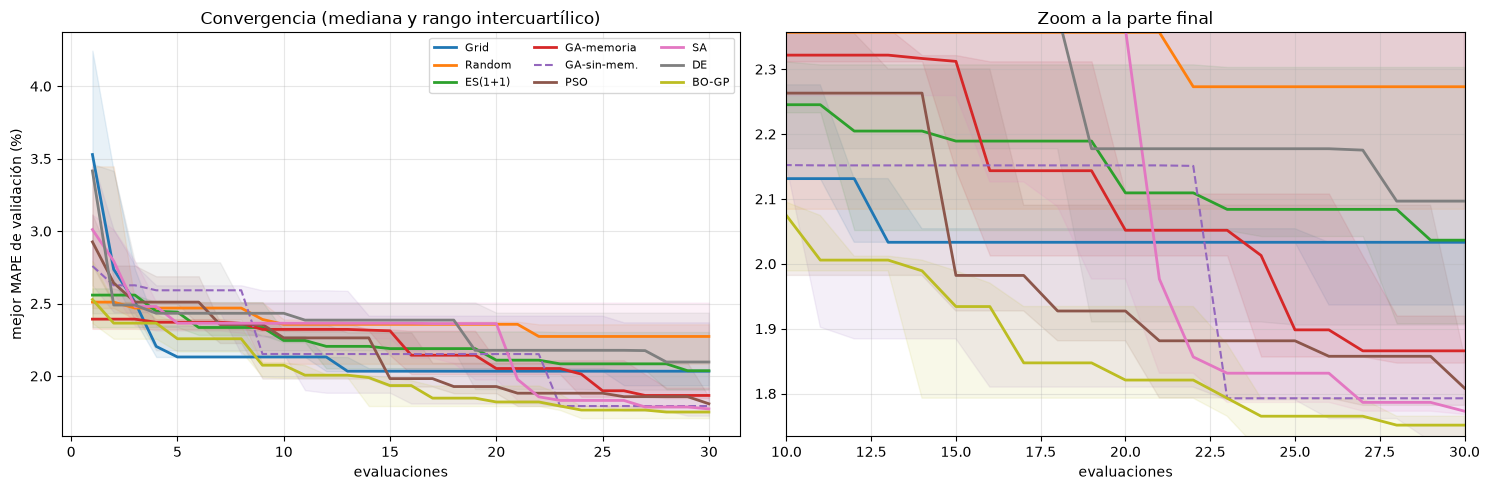

In [17]:
curvas = {a: np.array([r["curva"] for r in RES if r["alg"] == a]) for a in ALGOS}
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for a, C in curvas.items():
    med, q1, q3 = np.median(C, 0), np.percentile(C, 25, 0), np.percentile(C, 75, 0)
    x = np.arange(1, B + 1)
    for ax in axs:
        ax.plot(x, med, color=COLORES[a], lw=2 if a != "GA-sin-mem." else 1.5, ls="--" if a == "GA-sin-mem." else "-", label=a)
        ax.fill_between(x, q1, q3, color=COLORES[a], alpha=0.10)
axs[0].set_title("Convergencia (mediana y rango intercuartílico)"); axs[0].set_xlabel("evaluaciones"); axs[0].set_ylabel("mejor MAPE de validación (%)")
lo = min(np.median(C[:, -1]) for C in curvas.values()); hi = np.median(curvas["Random"][:, 9])
axs[1].set_ylim(lo * 0.99, hi); axs[1].set_xlim(10, B)
axs[1].set_title("Zoom a la parte final"); axs[1].set_xlabel("evaluaciones")
axs[0].legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

### 9.2 Distribución final y significancia

Con 5 réplicas la potencia estadística es baja, así que usamos pruebas **no paramétricas**:

- **Kruskal-Wallis** sobre el MAPE final de las 9 variantes (¿hay *alguna* diferencia?).
- **Mann-Whitney** (exacto) de cada metaheurística contra *Random Search*, con corrección de **Holm** por comparaciones múltiples.
- Además del valor final, el **área bajo la curva de convergencia** (promedio del mejor-hasta-ahora sobre las $B$ evaluaciones), que mide también qué tan rápido se llega y es menos ruidoso que un solo número.

Un $p$ pequeño aquí significa "diferencia detectable con esta muestra", no "el algoritmo X es mejor en general": los resultados dependen del problema, del presupuesto y de los parámetros de cada algoritmo (que no se ajustaron).

Kruskal-Wallis (MAPE final):  H=13.28, p=0.1025
Kruskal-Wallis (AUC curva):   H=8.36, p=0.3987

Comparación contra Random Search (Mann-Whitney exacto, Holm sobre 8 comparaciones por métrica):
métrica   algoritmo  mediana_alg  mediana_Random  p_MWU  p_Holm
  final        Grid       2.0332          2.2729 0.0952  0.4762
  final     ES(1+1)       2.0364          2.2729 0.6905  1.0000
  final  GA-memoria       1.8659          2.2729 0.0556  0.3889
  final GA-sin-mem.       1.7928          2.2729 0.4206  1.0000
  final         PSO       1.8085          2.2729 0.0556  0.3889
  final          SA       1.7729          2.2729 0.6905  1.0000
  final          DE       2.0966          2.2729 1.0000  1.0000
  final       BO-GP       1.7514          2.2729 0.0159  0.1270
    AUC        Grid       2.2120          2.4027 0.4206  1.0000
    AUC     ES(1+1)       2.1837          2.4027 0.6905  1.0000
    AUC  GA-memoria       2.2164          2.4027 0.4206  1.0000
    AUC GA-sin-mem.       2.3007        

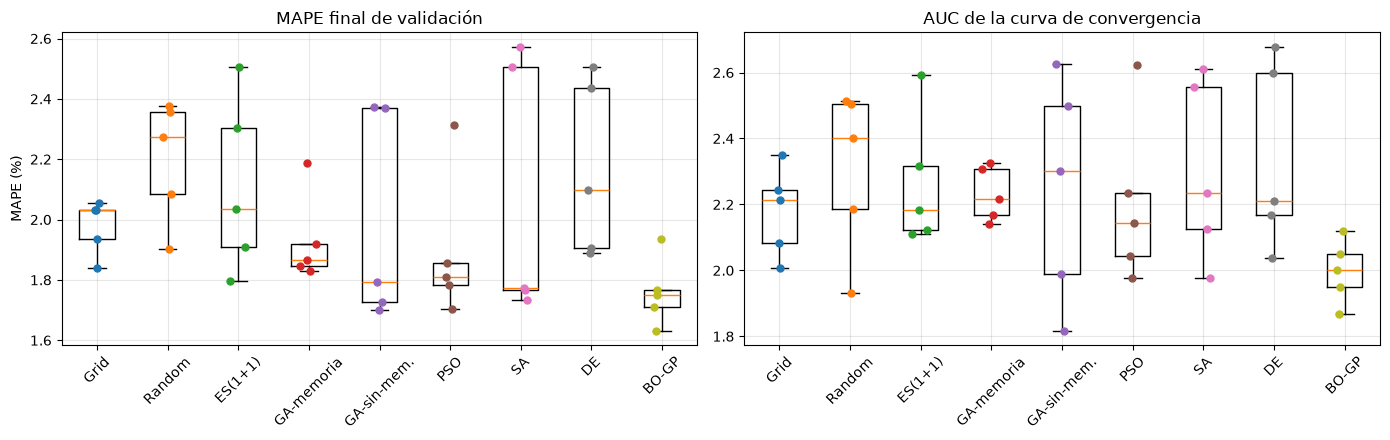

In [18]:
def holm(pvals):
    """Corrección de Holm-Bonferroni: devuelve p ajustados."""
    p = np.asarray(pvals); orden = np.argsort(p); m = len(p); aj = np.empty(m); prev = 0
    for rank, i in enumerate(orden):
        prev = max(prev, min(1.0, (m - rank) * p[i])); aj[i] = prev
    return aj

grupos_f   = {a: np.array([r["f"] for r in RES if r["alg"] == a]) for a in ALGOS}
grupos_auc = {a: curvas[a].mean(1) for a in ALGOS}
print("Kruskal-Wallis (MAPE final):  H=%.2f, p=%.4f" % stats.kruskal(*grupos_f.values()))
print("Kruskal-Wallis (AUC curva):   H=%.2f, p=%.4f" % stats.kruskal(*grupos_auc.values()))

otros = [a for a in ALGOS if a != "Random"]
filas = []
for nombre, g in (("final", grupos_f), ("AUC", grupos_auc)):
    ps = [stats.mannwhitneyu(g[a], g["Random"], alternative="two-sided", method="exact").pvalue for a in otros]
    ph = holm(ps)
    for a, p_, pa in zip(otros, ps, ph):
        filas.append({"métrica": nombre, "algoritmo": a, "mediana_alg": np.median(g[a]), "mediana_Random": np.median(g["Random"]),
                      "p_MWU": p_, "p_Holm": pa})
sig = pd.DataFrame(filas)
print("\nComparación contra Random Search (Mann-Whitney exacto, Holm sobre 8 comparaciones por métrica):")
print(sig.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for j, (titulo, g) in enumerate((("MAPE final de validación", grupos_f), ("AUC de la curva de convergencia", grupos_auc))):
    ax[j].boxplot(list(g.values()), showfliers=False); ax[j].set_xticks(range(1, len(g) + 1)); ax[j].set_xticklabels(list(g.keys()))
    for i, a in enumerate(g):
        ax[j].scatter(np.full(len(g[a]), i + 1) + np.random.default_rng(i).normal(0, 0.05, len(g[a])), g[a], color=COLORES[a], s=25, zorder=3)
    ax[j].set_title(titulo); ax[j].tick_params(axis="x", rotation=45)
ax[0].set_ylabel("MAPE (%)"); plt.tight_layout(); plt.show()

**Lectura estadística (honesta).** Mira la prueba global y las comparaciones con corrección de Holm: con 5 réplicas por algoritmo y la dispersión observada, **ninguna metaheurística supera a la búsqueda aleatoria de forma estadísticamente significativa** una vez corregidas las comparaciones múltiples (Kruskal-Wallis global tampoco rechaza al 5%). Hay tendencias: la optimización bayesiana es la que más se acerca a la significancia antes de la corrección, y la búsqueda aleatoria queda con la peor mediana. Esto es coherente con lo que se sabe de HPO: con presupuestos pequeños, la búsqueda aleatoria es una línea base difícil de batir, y distinguir métodos exige más réplicas (el ejercicio 1 propone aumentar $B$ y $R$). **No** conviene concluir "el algoritmo X es mejor que el Y" con este diseño.

### 9.3 Mejores hiperparámetros encontrados

Para cada algoritmo mostramos la **mejor corrida** (según MAPE de validación). Es información interesante *y* un recordatorio: distintos algoritmos pueden converger a configuraciones de familias distintas con errores similares (paisaje con muchas soluciones casi equivalentes).

In [19]:
mejores = {a: min((r for r in RES if r["alg"] == a), key=lambda r: r["f"]) for a in ALGOS}
filas = [{"algoritmo": a, "MAPE_val": r["f"], "familia": r["cfg"]["familia"], "lags": r["cfg"]["lags"],
          "hiperparámetros": {k: v for k, v in r["cfg"].items() if k not in ("familia", "lags")}} for a, r in mejores.items()]
pd.set_option("display.max_colwidth", 110, "display.width", 200)
print(pd.DataFrame(filas).round(3).sort_values("MAPE_val").to_string(index=False))
fam_final = pd.Series([r["cfg"]["familia"] for r in RES]).value_counts()
print("\nFamilia del mejor individuo en las", len(RES), "corridas:", fam_final.to_dict())

  algoritmo  MAPE_val familia lags                                                                             hiperparámetros
      BO-GP     1.630     mlp    B   {'unidades': 48, 'capas': 3, 'lr': 0.00765, 'alpha': 0.0618, 'act': 'relu', 'epocas': 46}
GA-sin-mem.     1.702     mlp    C {'unidades': 34, 'capas': 3, 'lr': 0.00851, 'alpha': 0.000567, 'act': 'relu', 'epocas': 52}
        PSO     1.703     mlp    B      {'unidades': 39, 'capas': 2, 'lr': 0.00223, 'alpha': 0.1, 'act': 'relu', 'epocas': 57}
         SA     1.733     mlp    B     {'unidades': 40, 'capas': 2, 'lr': 0.01, 'alpha': 0.00645, 'act': 'relu', 'epocas': 37}
    ES(1+1)     1.795     mlp    B      {'unidades': 21, 'capas': 2, 'lr': 0.01, 'alpha': 0.0407, 'act': 'relu', 'epocas': 51}
 GA-memoria     1.829     mlp    A      {'unidades': 26, 'capas': 3, 'lr': 0.00881, 'alpha': 0.1, 'act': 'relu', 'epocas': 59}
       Grid     1.839     mlp    A     {'unidades': 18, 'capas': 2, 'lr': 0.00316, 'alpha': 0.01, 'act': 'relu'

**Lectura.** En la mayoría de las corridas el mejor individuo pertenece a la familia MLP, seguida por gradient boosting; Ridge es la mejor solo ocasionalmente. Las mejores configuraciones MLP comparten rasgos cualitativos (activación ReLU, 2-3 capas, tasa de aprendizaje en la mitad alta del rango en la mayoría de los casos): el optimizador descubre la región buena, aunque los valores exactos varían entre corridas porque el paisaje tiene muchas configuraciones casi equivalentes.

### 9.4 Ablación: el valor de la memoria

El GA de estado estable corre dos veces: **con memoria** (los duplicados no cuestan evaluación y se evita proponerlos) y **sin memoria** (cada llamada cuesta). Con el mismo presupuesto $B$, la versión con memoria puede explorar más configuraciones *distintas*. Cuantificamos cuántas llamadas duplicadas se evitan y cuántas configuraciones efectivas distintas se evalúan.

In [20]:
# Recomputamos las corridas para contar configuraciones distintas visitadas por cada variante de GA
def corrida_traza(nombre, semilla, B):
    alg, ch = ALGOS[nombre]; ev = Evaluador(P, B, cuenta_hits=ch)
    rng = np.random.default_rng(10_000 * (list(ALGOS).index(nombre) + 1) + semilla)
    try: alg(ev, rng)
    except Agotado: pass
    return ev
filas = []
for nombre in ("GA-memoria", "GA-sin-mem."):
    for s in range(R):
        ev_ = corrida_traza(nombre, s, B)
        filas.append({"variante": nombre, "semilla": s, "evaluaciones_cargadas": ev_.usado, "llamadas": ev_.llamadas,
                      "configs_distintas": len(ev_.local), "mejor_MAPE": ev_.mejor_f})
abl = pd.DataFrame(filas).groupby("variante").mean(numeric_only=True).drop(columns="semilla")
print(abl.round(3).to_string())
print("\nSin memoria, las llamadas duplicadas (cargadas pero sin información nueva):",
      round((abl.loc["GA-sin-mem.", "evaluaciones_cargadas"] - abl.loc["GA-sin-mem.", "configs_distintas"]), 2), "por corrida en promedio")

             evaluaciones_cargadas  llamadas  configs_distintas  mejor_MAPE
variante                                                                   
GA-memoria                    30.0      30.0               30.0       1.930
GA-sin-mem.                   30.0      30.0               27.2       1.993

Sin memoria, las llamadas duplicadas (cargadas pero sin información nueva): 2.8 por corrida en promedio


**Lectura.** Con el mismo presupuesto, la variante sin memoria gasta una parte de sus evaluaciones en configuraciones repetidas (la cifra impresa), mientras la variante con memoria evalúa $B$ configuraciones distintas. En este experimento, el efecto sobre el MAPE final es pequeño comparado con la dispersión entre réplicas (no es detectable con 5 réplicas): el beneficio de la memoria aquí es **ahorrar cómputo** y garantizar exploración sin repetición, y crecerá cuando las poblaciones converjan y se repitan más (espacios discretos pequeños, presupuestos mayores).

## 10. Predicción vs real en el conjunto de prueba

Hasta aquí solo hemos visto el conjunto de validación, que **el optimizador usó para decidir**. Para evaluar de verdad hay que:

1. **Re-evaluar** la mejor configuración de cada corrida con **varias semillas de entrenamiento** (3) sobre validación: así se desinfla el ruido que el optimizador "explotó".
2. **Reentrenar con train + validación** (ya no hace falta separar validación) y evaluar en **prueba** (bloque final, nunca consultado), con 2 semillas.

Esto es el análogo, en series de tiempo, del *nested resampling*: la selección ocurre dentro del bloque train/val, la estimación del error fuera. (Una versión más completa usa *rolling-origin*: varios cortes temporales con su propio bloque de prueba posterior; aquí un solo corte por brevedad.)

In [21]:
idx_trva = np.concatenate([P.itr, P.iva])
def eval_multisemilla(cfg, semillas=(0, 1, 2)):
    return np.array([mape(P.y[P.iva], P.ajustar_predecir(cfg, P.itr, P.iva, seed=s)) for s in semillas])
def eval_test(cfg, semillas=(0, 1)):
    m, rm = [], []
    for s in semillas:
        p = P.ajustar_predecir(cfg, idx_trva, P.ite, seed=s); m.append(mape(P.y[P.ite], p)); rm.append(rmse(P.y[P.ite], p))
    return np.mean(m), np.mean(rm)

t0 = time.perf_counter()
for r in RES:
    r["val_multi"] = eval_multisemilla(r["cfg"])
    r["test_mape"], r["test_rmse"] = eval_test(r["cfg"])
print(f"Re-evaluación y prueba final: {time.perf_counter() - t0:.0f}s")
fin = pd.DataFrame([{"alg": r["alg"], "val_interno": r["f"], "val_5sem": r["val_multi"].mean(),
                     "test_MAPE": r["test_mape"], "test_RMSE": r["test_rmse"]} for r in RES])
fin["optimismo_val"] = fin["val_5sem"] - fin["val_interno"]
resumen_fin = fin.groupby("alg", sort=False).mean(numeric_only=True)
print(resumen_fin.round(3).sort_values("test_MAPE").to_string())
print(f"\nReferencia ingenua (lag-168) en test: MAPE {base_naive:.2f}%")

Re-evaluación y prueba final: 18s
             val_interno  val_5sem  test_MAPE  test_RMSE  optimismo_val
alg                                                                    
BO-GP              1.758     1.949      1.573     20.992          0.191
Grid               1.979     2.083      1.746     23.058          0.103
PSO                1.893     1.926      1.797     23.726          0.033
GA-sin-mem.        1.993     2.181      1.922     25.844          0.188
SA                 2.071     2.096      1.922     25.694          0.025
Random             2.198     2.212      1.926     26.201          0.014
GA-memoria         1.930     2.073      1.957     26.157          0.143
ES(1+1)            2.110     2.178      2.102     28.589          0.068
DE                 2.167     2.248      2.158     29.522          0.081

Referencia ingenua (lag-168) en test: MAPE 4.40%


**Lectura: del fitness a la prueba.** Tres fenómenos, todos visibles en la tabla y el gráfico:

1. `val_5sem` > `val_interno` en prácticamente todos los algoritmos: el valor que vio el optimizador (una semilla) es **optimista** frente a la re-evaluación con varias semillas. Es el sesgo de seleccionar el mínimo de valores ruidosos: parte de la "mejora" encontrada era ruido de entrenamiento.
2. El MAPE de **prueba es menor** que el de validación re-evaluado (`val_5sem`) en todos los algoritmos. No es magia: el modelo final se reentrena con train+validación (más datos y más recientes) y el bloque de prueba es simplemente un período con otro nivel de dificultad. Esto recuerda que, en series de tiempo, la brecha val-prueba mezcla optimismo de selección y **deriva** entre bloques; por eso la comparación entre algoritmos debe hacerse dentro del mismo bloque.
3. Todas las configuraciones optimizadas están muy por debajo de la referencia ingenua, y las diferencias entre algoritmos en prueba son pequeñas frente a esa distancia: lo que importa es disponer de *una buena región* del espacio, no cuál metaheurística la encontró.

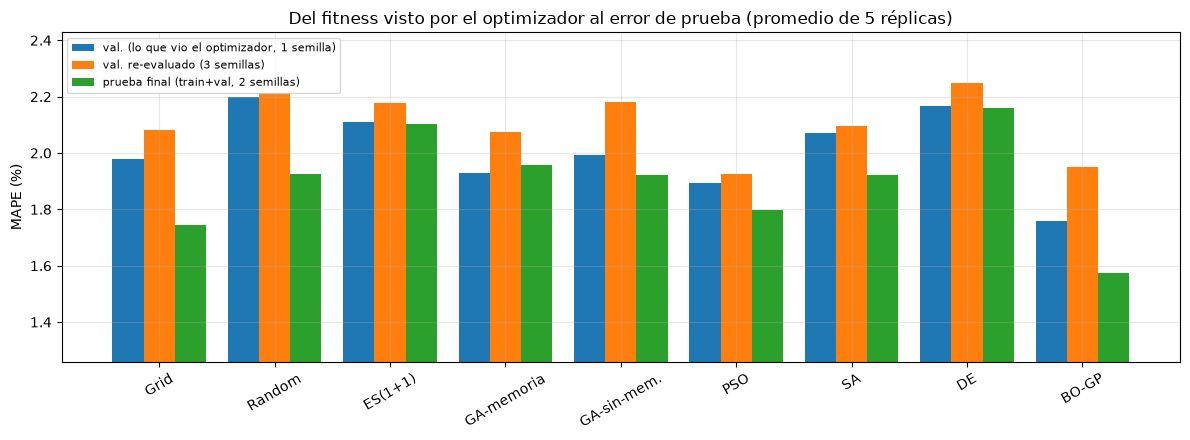

In [22]:
fig, ax = plt.subplots(figsize=(12, 4.5)); w = 0.27; x = np.arange(len(resumen_fin))
ax.bar(x - w, resumen_fin["val_interno"], w, label="val. (lo que vio el optimizador, 1 semilla)")
ax.bar(x, resumen_fin["val_5sem"], w, label="val. re-evaluado (3 semillas)")
ax.bar(x + w, resumen_fin["test_MAPE"], w, label="prueba final (train+val, 2 semillas)")
ax.set_xticks(x); ax.set_xticklabels(resumen_fin.index, rotation=30); ax.set_ylabel("MAPE (%)")
ax.set_ylim(resumen_fin.values[:, :3].min() * 0.8, resumen_fin.values[:, :3].max() * 1.08)
ax.set_title("Del fitness visto por el optimizador al error de prueba (promedio de 5 réplicas)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### Mejor modelo: predicción vs valor real

Elegimos la **configuración ganadora usando solo validación** (la corrida con menor MAPE de validación re-evaluado con 5 semillas; nunca el de prueba), y la comparamos contra dos referencias: el pronóstico ingenuo (misma hora de la semana anterior) y una configuración "por defecto" razonable (gradient boosting estándar con rezagos B), que representa lo que haría un practicante sin HPO.

Ganador (por validación): BO-GP  {'familia': 'mlp', 'lags': 'B', 'unidades': 48, 'capas': 3, 'lr': 0.00765, 'alpha': 0.0618, 'act': 'relu', 'epocas': 46}
                              MAPE %  RMSE MW
Ganador HPO (metaheurística)   1.544   20.307
GBR por defecto                2.201   29.545
Ingenuo lag-168                4.399   61.801


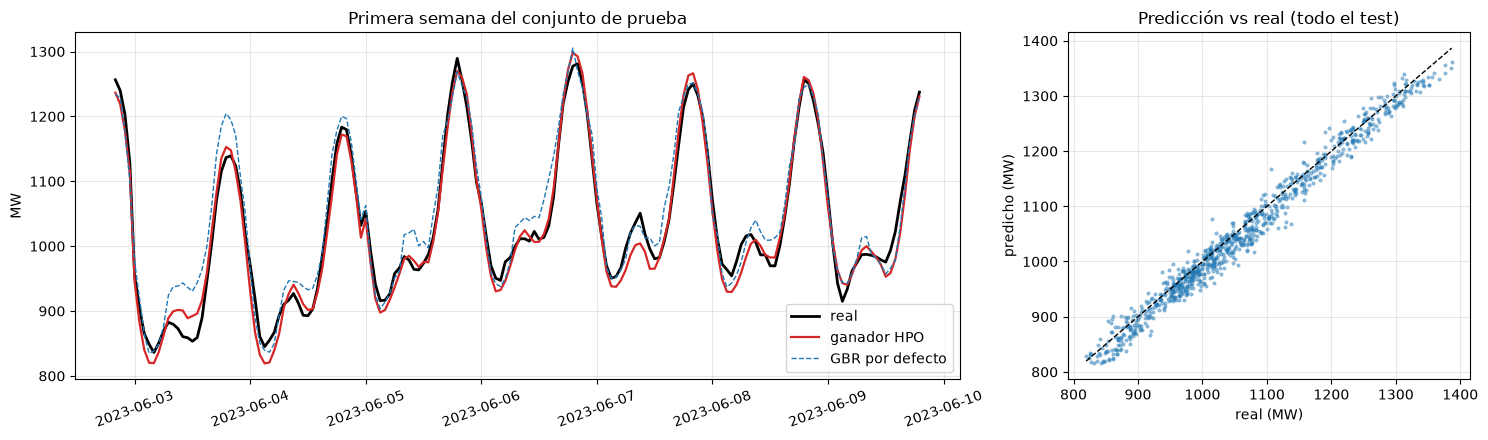

In [23]:
ganador = min(RES, key=lambda r: r["val_multi"].mean())
cfg_g = ganador["cfg"]
cfg_def = {"familia": "gbr", "lags": "B", "max_iter": 100, "max_depth": 6, "learning_rate": 0.1, "l2": 0.0, "min_leaf": 20}
p_g   = P.ajustar_predecir(cfg_g, idx_trva, P.ite, seed=0)          # una sola semilla: sin efecto de ensamble
p_def = P.ajustar_predecir(cfg_def, idx_trva, P.ite, seed=0)
y_te = P.y[P.ite]; p_naive = X_all["lag_168"].values[P.ite]
print(f"Ganador (por validación): {ganador['alg']}  {cfg_g}")
tab = pd.DataFrame({"MAPE %": [mape(y_te, p_g), mape(y_te, p_def), mape(y_te, p_naive)],
                    "RMSE MW": [rmse(y_te, p_g), rmse(y_te, p_def), rmse(y_te, p_naive)]},
                   index=["Ganador HPO (metaheurística)", "GBR por defecto", "Ingenuo lag-168"])
print(tab.round(3).to_string())

fechas = X_all.index[P.ite]; s7 = slice(0, 24 * 7)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(fechas[s7], y_te[s7], color="k", lw=2, label="real")
ax[0].plot(fechas[s7], p_g[s7], color="tab:red", lw=1.6, label="ganador HPO")
ax[0].plot(fechas[s7], p_def[s7], color="tab:blue", lw=1.0, ls="--", label="GBR por defecto")
ax[0].set_title("Primera semana del conjunto de prueba"); ax[0].set_ylabel("MW"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=20)
ax[1].scatter(y_te, p_g, s=4, alpha=0.4); lim = [y_te.min(), y_te.max()]; ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set_title("Predicción vs real (todo el test)"); ax[1].set_xlabel("real (MW)"); ax[1].set_ylabel("predicho (MW)")
plt.tight_layout(); plt.show()

**Lectura.** El modelo seleccionado por HPO sigue de cerca el ciclo diario y semanal de la demanda en la semana de prueba (panel izquierdo) y los puntos predicho-real se alinean sobre la diagonal (panel derecho). Frente a una configuración "razonable por defecto" de gradient boosting, el modelo ajustado reduce el error, y ambos superan ampliamente la referencia ingenua. Recuerda que el ganador se eligió **solo con validación**; en prueba podría haber sido otro, y la tabla anterior muestra que los algoritmos quedan cercanos entre sí.

## 11. Costo computacional y riesgo de sobreajuste al conjunto de validación

### 11.1 Costo en tiempo

El costo total de un HPO es $\text{costo}\approx B\cdot\bar c_{\text{eval}} + \text{sobrecosto del optimizador}$. En esta notebook $\bar c_{\text{eval}}$ es del orden de décimas de segundo y el sobrecosto del optimizador (operadores, ajuste del GP) es normalmente despreciable... salvo para la optimización bayesiana, cuyo sobrecosto crece con el número de puntos (inversión de la matriz de covarianza, $O(n^3)$) y con la maximización de la adquisición. Con un Transformer, $\bar c_{\text{eval}}$ sube a minutos u horas y el sobrecosto deja de importar: el único recurso relevante es el **número de evaluaciones** y cuánto se paraleliza.

Objetivo: MAPE de validación <= 2.273% (mediana final de Random Search tras 30 evaluaciones)
             t_eval_s  overhead_s  total_s  overhead_%  evals_para_igualar_Random  %_corridas_que_lo_logran
alg                                                                                                        
Grid            1.165       0.001    1.166       0.086                        4.0                     100.0
Random          0.902       0.001    0.903       0.111                        9.0                      60.0
ES(1+1)         1.148       0.002    1.151       0.196                       10.0                      60.0
GA-memoria      1.951       0.003    1.953       0.143                       16.0                     100.0
GA-sin-mem.     1.463       0.002    1.465       0.133                        8.0                      60.0
PSO             1.382       0.001    1.384       0.102                        8.5                      80.0
SA              1.141       0.002    1.143 

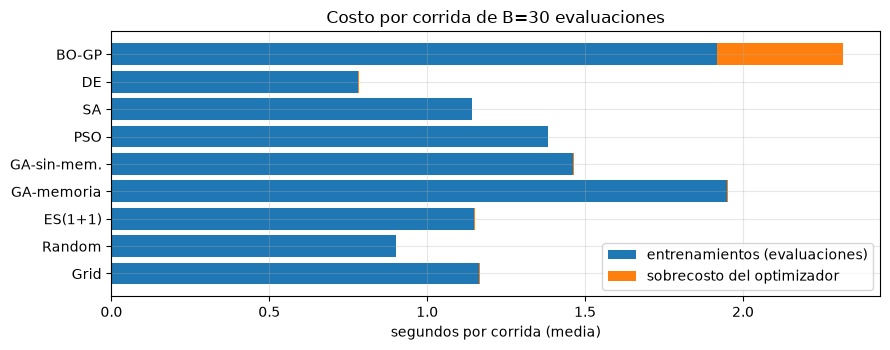

In [24]:
costo = tabla[["t_eval_s", "overhead_s"]].copy()
costo["total_s"] = costo.sum(axis=1); costo["overhead_%"] = 100 * costo["overhead_s"] / costo["total_s"]
# evaluaciones necesarias para alcanzar el nivel mediano final de Random Search
objetivo = np.median(grupos_f["Random"])
def evals_hasta(curva, tgt):
    h = np.where(curva <= tgt)[0]; return h[0] + 1 if len(h) else np.nan
costo["evals_para_igualar_Random"] = [np.nanmedian([evals_hasta(c, objetivo) for c in curvas[a]]) for a in costo.index]
costo["%_corridas_que_lo_logran"] = [100 * np.mean([not np.isnan(evals_hasta(c, objetivo)) for c in curvas[a]]) for a in costo.index]
print(f"Objetivo: MAPE de validación <= {objetivo:.3f}% (mediana final de Random Search tras {B} evaluaciones)")
print(costo.round(3).to_string())
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(costo.index, costo["t_eval_s"], label="entrenamientos (evaluaciones)"); ax.barh(costo.index, costo["overhead_s"], left=costo["t_eval_s"], label="sobrecosto del optimizador")
ax.set_xlabel("segundos por corrida (media)"); ax.legend(); ax.set_title("Costo por corrida de B=%d evaluaciones" % B); plt.tight_layout(); plt.show()

**Lectura del costo.** (i) El **sobrecosto del optimizador** es despreciable (< 1% del tiempo total) para todos los métodos *excepto* la optimización bayesiana, donde el ajuste del GP y la maximización de la adquisición son una fracción apreciable ya con $B=30$ y crecen con $n^3$. (ii) La columna de "evaluaciones para igualar a Random" es una medida de **velocidad hacia una meta fija**: valores bajos significan que el método alcanza pronto el nivel que Random logra al final, y el porcentaje de corridas indica la fiabilidad. (iii) El tiempo por corrida depende de dónde se muestrea; en un Transformer esa diferencia se amplifica.

### 11.2 Sobreajuste al conjunto de validación (el "maldición del ganador")

Al elegir el **mínimo** de $n$ valores ruidosos de validación, el mínimo está sesgado a la baja: parte de la "mejora" es ruido o particularidad del bloque de validación que el optimizador explotó. Cuantos más candidatos se evalúan (y cuanto más inteligente es la búsqueda), mayor es el sesgo. Además, en series temporales hay **deriva** entre bloques (aquí la tendencia): el error de prueba no tiene por qué coincidir con el de validación ni siquiera para una configuración fija.

Lo cuantificamos de dos formas: (a) con 60 configuraciones aleatorias, el MAPE de validación del *mejor hasta el momento* frente al MAPE de **prueba de esa misma configuración** (modelo entrenado solo con train en ambos casos, para aislar el efecto de selección); (b) la correlación de rangos entre validación y prueba.

Correlación de rangos val-test entre las 60 configuraciones: rho=0.92 (p=9.2e-26)
Tras 60 candidatos: MAPE val del mejor = 2.011%  vs  MAPE test de ese mismo modelo = 2.139%
Mediana de MAPE test de las 60 configs = 3.280% | mejor MAPE test posible entre las 60 = 2.139%


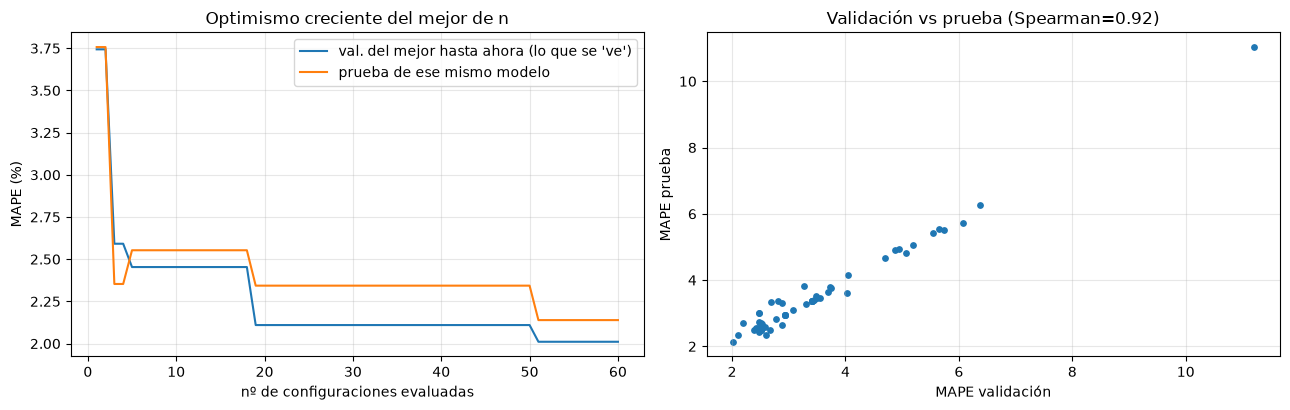

In [25]:
rng_o = np.random.default_rng(555)
cfgs = [decodificar(rng_o.random(D)) for _ in range(60)]
val_c, te_c = [], []
for c in cfgs:
    k = clave(c)
    val_c.append(ALMACEN[k][0] if k in ALMACEN else mape(P.y[P.iva], P.ajustar_predecir(c, P.itr, P.iva, seed=0)))
    te_c.append(mape(P.y[P.ite], P.ajustar_predecir(c, P.itr, P.ite, seed=0)))
val_c, te_c = np.array(val_c), np.array(te_c)
inc = np.minimum.accumulate(val_c); jinc = np.array([np.argmin(val_c[:i + 1]) for i in range(60)])
rho, p_rho = stats.spearmanr(val_c, te_c)
print(f"Correlación de rangos val-test entre las 60 configuraciones: rho={rho:.2f} (p={p_rho:.1e})")
print(f"Tras 60 candidatos: MAPE val del mejor = {inc[-1]:.3f}%  vs  MAPE test de ese mismo modelo = {te_c[jinc[-1]]:.3f}%")
print(f"Mediana de MAPE test de las 60 configs = {np.median(te_c):.3f}% | mejor MAPE test posible entre las 60 = {te_c.min():.3f}%")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(np.arange(1, 61), inc, label="val. del mejor hasta ahora (lo que se 've')")
ax[0].plot(np.arange(1, 61), te_c[jinc], label="prueba de ese mismo modelo")
ax[0].set_xlabel("nº de configuraciones evaluadas"); ax[0].set_ylabel("MAPE (%)"); ax[0].set_title("Optimismo creciente del mejor de n"); ax[0].legend()
ax[1].scatter(val_c, te_c, s=15); ax[1].set_xlabel("MAPE validación"); ax[1].set_ylabel("MAPE prueba"); ax[1].set_title(f"Validación vs prueba (Spearman={rho:.2f})")
plt.tight_layout(); plt.show()

In [26]:
brecha = fin.assign(brecha_test_menos_val=fin["test_MAPE"] - fin["val_interno"]).groupby("alg", sort=False)["brecha_test_menos_val"].agg(["mean", "std"])
print("Brecha (MAPE de prueba - MAPE de validación visto por el optimizador), promedio y desv. entre 5 réplicas:")
print(brecha.round(3).to_string())

Brecha (MAPE de prueba - MAPE de validación visto por el optimizador), promedio y desv. entre 5 réplicas:
              mean    std
alg                      
Grid        -0.233  0.217
Random      -0.272  0.240
ES(1+1)     -0.008  0.186
GA-memoria   0.027  0.189
GA-sin-mem. -0.071  0.100
PSO         -0.095  0.071
SA          -0.148  0.203
DE          -0.009  0.214
BO-GP       -0.185  0.085


**Lectura.** (i) Entre las 60 configuraciones aleatorias la correlación de rangos validación-prueba es alta: validación **sí sirve para ordenar** configuraciones, que es lo que necesita un optimizador. (ii) Pero el *mejor* de $n$ candidatos tiene un MAPE de validación menor que el de prueba de ese mismo modelo (con los dos entrenados solo con train): el optimismo del ganador es real y crece con $n$ (panel izquierdo). (iii) La brecha de la tabla final (prueba menos validación visto) es negativa en casi todos los algoritmos por la razón explicada arriba (reentrenar con más datos, deriva): **no** es evidencia de ausencia de optimismo; para aislarlo hay que comparar a igualdad de datos, como se hizo en (ii). **Receta**: re-evaluar con varias semillas, reservar un bloque de prueba temporal intacto y, si el presupuesto lo permite, usar *rolling-origin*.

## 12. Cómo llevar esto a un Transformer/PyTorch (sin ejecutar)

Todo el esqueleto de esta notebook (codificación en $[0,1]^d$, evaluador con caché y presupuesto, optimizadores, validación temporal con prueba final) se transfiere tal cual. Lo que **cambia** es la función `ajustar_predecir`, y con ella casi todas las decisiones prácticas:

| Aspecto | Esta notebook (sklearn) | Transformer en PyTorch |
|---|---|---|
| Costo por evaluación $\bar c_{\text{eval}}$ | ~0.1 s | minutos a horas (CPU/GPU); $B$ típico de 20-100 |
| Ruido del fitness | pequeño (semilla fija) | grande: inicialización, `dropout`, orden de lotes, no determinismo de GPU; conviene 2-3 semillas en la fase final |
| Memoria / caché | clave por configuración efectiva | **imprescindible**; persistir a disco (JSON/SQLite) para reanudar corridas; guardar también *checkpoints* del mejor |
| Qué optimizar | MAPE de validación | MAPE (o RMSE/pérdida Huber) de validación **temporal**, evaluado tras la última época o con *early stopping* |
| Paralelismo | secuencial | evaluaciones en paralelo en varias GPUs/nodos: favorecen DE, GA de estado estable asíncrono y random search sobre BO secuencial |
| Reducción de costo | subconjuntos de datos, modelos pequeños | **multi-fidelidad**: pocas épocas al inicio, *successive halving*/Hyperband, submuestreo de series, ventanas más cortas |

### 12.1 *Early stopping* y épocas como hiperparámetro

En el proyecto original `num_epochs` era un gen del individuo (10, 20, 50, 100), lo que hace que el costo de evaluar dependa directamente del individuo. Con *early stopping* sobre una porción **temporalmente posterior** del bloque de entrenamiento, `num_epochs` pasa a ser un **tope** y el entrenamiento se detiene solo cuando deja de mejorar: se reduce el costo medio por evaluación y el gen `epocas` deja de ser una decisión del optimizador. Precauciones: (i) el *early stopping* usa un bloque distinto del de validación del optimizador (si no, se agrega otra vía de sobreajuste a validación); (ii) hay que registrar el número real de épocas como parte del resultado de la evaluación.

### 12.2 Subespacio de arquitectura y restricciones

Un Transformer para pronóstico tiene un subespacio *arquitectónico* con dependencias duras:

```python
# Esquema (no se ejecuta): decodificador válido por construcción para un Transformer
d_model  = {16, 32, 64, 128}[idx(u0)]            # categórico
n_heads  = divisores(d_model) ∩ {1, 2, 4, 8}[idx(u1)]   # el gen indexa los divisores factibles (sección 2)
n_layers = entero(u2, 1, 4)
d_ff     = d_model * {1, 2, 4}[idx(u3)]          # relación con d_model: se expresa como multiplicador
dropout  = lineal(u4, 0.0, 0.3)
lr       = log(u5, 1e-4, 1e-2)                   # escala log
seq_len  = {24, 48, 96, 168}[idx(u6)]            # análogo del conjunto de rezagos (afecta el tamaño de los datos)
batch    = {32, 64, 128}[idx(u7)]
```

Observaciones: **(a)** expresar los hiperparámetros dependientes como *razones* ($d_{ff}/d_{model}$) evita infactibilidad; **(b)** `seq_len` cambia el tamaño del conjunto de entrenamiento y la memoria, por lo que es el gen que más influye en costo; **(c)** conviene **acotar** el espacio con conocimiento previo (por ejemplo, no explorar $d_{\text{model}}=512$ en una serie corta) en vez de depender del optimizador para descubrirlo; **(d)** con presupuestos tan pequeños, un GA/DE con población de 10 consume toda la corrida en la población inicial: reducir la población (5-8) o usar una $(1+1)$-ES con reinicios es más sensato.

### 12.3 Lista de verificación al migrar

1. Fijar semillas de `torch`, `numpy`, y `torch.backends.cudnn.deterministic` si se necesita caché fiable; de lo contrario, tratar $f$ como ruidosa y re-evaluar al final.
2. Medir $\bar c_{\text{eval}}$ en 3-5 configuraciones antes de fijar $B$ y el número de réplicas.
3. Validación temporal con prueba final intacta; si hay deriva (estacionalidad anual), usar *rolling-origin* con al menos un ciclo anual en la ventana.
4. Registrar **todo** (configuración, semilla, tiempo, época de parada, curva de validación) en un archivo: la caché también es el registro experimental.
5. Comparar siempre contra un modelo base sin HPO y contra *random search* con el **mismo** presupuesto.

## 13. Ventajas, limitaciones y resumen

### Metaheurísticas para HPO: cuándo sí y cuándo no

| | Ventajas | Limitaciones |
|---|---|---|
| **Grid** | Reproducible, trivial de paralelizar | Crece exponencialmente; desperdicia evaluaciones en dimensiones irrelevantes |
| **Random** | Sorprendentemente fuerte, sin parámetros, paralelo | No aprende de lo ya evaluado |
| **ES(1+1)** | Mínimo costo de implementación, auto-adaptación de $\sigma$, ideal con presupuesto minúsculo | Una sola trayectoria: puede quedar atrapada; sensible al punto inicial |
| **GA con memoria** | Maneja bien espacios mixtos, paralelizable de forma asíncrona, la caché evita repetir | Varios parámetros (población, presión de selección, mutación) que también hay que ajustar |
| **PSO** | Pocos parámetros, bueno en espacios continuos | Categóricas mal representadas; la población inicial consume buena parte del presupuesto |
| **SA** | Simple, una sola solución, garantías asintóticas | Requiere calibrar el calendario de temperatura para el rango del fitness |
| **DE** | Robusto en continuos y con pocos parámetros; usado en la literatura de referencia | Necesita poblaciones medianas: costoso con $B$ pequeño |
| **BO con GP** | Muy eficiente en muestras en espacios continuos de baja dimensión | Sobrecosto $O(n^3)$, categóricas/condicionales difíciles, sensible al kernel |

### Resumen

- HPO es optimización **de caja negra, costosa, ruidosa, mixta y condicional**; la codificación en $[0,1]^d$ con decodificador válido por construcción permite usar el mismo optimizador sobre todo tipo de variable.
- Comparar algoritmos exige **presupuesto igual, réplicas y pruebas no paramétricas**; con pocas réplicas, las conclusiones finas son frágiles.
- La **memoria** (memoización por configuración efectiva) es gratis y evita gastar presupuesto en duplicados; los genes inactivos de ramas condicionales la hacen más valiosa aún.
- El fitness visto por el optimizador es **optimista**: hay que re-evaluar con varias semillas y reservar un conjunto de **prueba temporal intacto**.
- En un Transformer, lo que domina es el costo por evaluación: de ahí multi-fidelidad, *early stopping*, caché persistente y paralelismo asíncrono.

Siguiente: [17 · selección de características con metaheurísticas](17-seleccion-de-caracteristicas-metaheuristicas.ipynb), donde el individuo es binario (qué variables entran) y la parsimonia entra al fitness.

### Ejercicios propuestos

1. **Presupuesto.** Repite el experimento con $B\in\{20,40,80\}$. ¿Cambia el orden de los algoritmos? Grafica el error final vs $B$.
2. **Parámetros de los optimizadores.** Ajusta $\mu$ del GA ($4,\dots,20$) y $\sigma$ de la ES con una grilla pequeña y 5 réplicas por punto (nota: es *ajuste de parámetros*, ver [15](../05-evaluacion-y-ajuste/15-ajuste-de-parametros.ipynb)). ¿Cuánto del resultado depende de esos parámetros?
3. **Fitness ruidoso.** Cambia el fitness para promediar 3 semillas (¿sigue valiendo la caché?). Mide cuánto baja el optimismo de la sección 11 y cuánto sube el costo.
4. **Penalizar el costo.** Define $f'(\lambda)=\text{MAPE}+\beta\,\log(t_{\text{entrenamiento}})$ y busca el frente de Pareto error-tiempo (ver [12 · multiobjetivo](../04-topicos-avanzados/12-optimizacion-multiobjetivo.ipynb)).
5. **Rolling-origin.** Reemplaza el corte único train/val por 3 cortes temporales y promedia el MAPE (¿cambia el ganador?).
6. **Operador de reparación.** Añade un gen `n_heads` con la restricción de divisibilidad de la sección 2 a un modelo MLP ficticio y verifica por qué la penalización es peor que la reparación en número de evaluaciones útiles.
7. **Algoritmo híbrido.** Combina BO (primeras 15 evaluaciones) con ES(1+1) local desde el mejor encontrado ([13 · híbridos](../04-topicos-avanzados/13-metodos-hibridos-y-paralelos.ipynb)).

### Referencias

- Abd Elaziz, M. et al. (2021). *Advanced metaheuristic optimization techniques in applications of deep neural networks: a review.* Neural Computing and Applications, 33.
- Bacanin, N., Stoean, C., Zivkovic, M., Rakic, M., Strulak-Wójcikiewicz, R. y Stoean, R. (2023). *On the Benefits of Using Metaheuristics in the Hyperparameter Tuning of Deep Learning Models for Energy Load Forecasting.* Energies, 16(3), 1434.
- Bergstra, J. y Bengio, Y. (2012). *Random Search for Hyper-Parameter Optimization.* Journal of Machine Learning Research, 13.
- Bergstra, J., Bardenet, R., Bengio, Y. y Kégl, B. (2011). *Algorithms for Hyper-Parameter Optimization.* NeurIPS.
- Feurer, M. y Hutter, F. (2019). *Hyperparameter Optimization.* En Hutter, Kotthoff y Vanschoren (eds.), *Automated Machine Learning: Methods, Systems, Challenges.* Springer.
- Hansen, N. y Ostermeier, A. (2001). *Completely Derandomized Self-Adaptation in Evolution Strategies.* Evolutionary Computation, 9(2).
- Hutter, F., Hoos, H. H. y Leyton-Brown, K. (2011). *Sequential Model-Based Optimization for General Algorithm Configuration.* LION 5.
- Jones, D. R., Schonlau, M. y Welch, W. J. (1998). *Efficient Global Optimization of Expensive Black-Box Functions.* Journal of Global Optimization, 13.
- Kennedy, J. y Eberhart, R. (1995). *Particle Swarm Optimization.* Proc. IEEE International Conference on Neural Networks.
- Kirkpatrick, S., Gelatt, C. D. y Vecchi, M. P. (1983). *Optimization by Simulated Annealing.* Science, 220.
- Lessmann, S., Stahlbock, R. y Crone, S. F. (2005). *Optimizing Hyperparameters of Support Vector Machines by Genetic Algorithms.*
- Li, L., Jamieson, K., DeSalvo, G., Rostamizadeh, A. y Talwalkar, A. (2018). *Hyperband: A Novel Bandit-Based Approach to Hyperparameter Optimization.* Journal of Machine Learning Research, 18.
- Real, E., Aggarwal, A., Huang, Y. y Le, Q. V. (2019). *Regularized Evolution for Image Classifier Architecture Search.* AAAI.
- Rechenberg, I. (1973). *Evolutionsstrategie: Optimierung technischer Systeme nach Prinzipien der biologischen Evolution.* Frommann-Holzboog.
- Sen, A., Mazumder, A. R. y Sen, U. (2023). *Differential Evolution Algorithm based Hyper-Parameters Selection of Transformer Neural Network Model for Load Forecasting.* IEEE Symposium Series on Computational Intelligence (SSCI).
- Snoek, J., Larochelle, H. y Adams, R. P. (2012). *Practical Bayesian Optimization of Machine Learning Algorithms.* NeurIPS.
- Storn, R. y Price, K. (1997). *Differential Evolution: A Simple and Efficient Heuristic for Global Optimization over Continuous Spaces.* Journal of Global Optimization, 11.
- Vaswani, A. et al. (2017). *Attention Is All You Need.* NeurIPS.